## Predicting the price of an Airbnb listing

In [791]:
import pandas as pd
import numpy as np
import seaborn as sb
import matplotlib.pyplot as plt 
import re
from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import AdaBoostRegressor
from sklearn.model_selection import cross_val_predict
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
from sklearn.ensemble import AdaBoostRegressor

sb.set()

In [792]:
listings_csv= pd.read_csv(r"C:\Users\linsh\Documents\LIN\NTU\MA0218\archive\listings.csv")

In [793]:
pd.set_option('display.max_column', 100)
df = pd.DataFrame(listings_csv)
df

,id,listing_url,scrape_id,last_scraped,name,summary,space,description,experiences_offered,neighborhood_overview,notes,transit,thumbnail_url,medium_url,picture_url,xl_picture_url,host_id,host_url,host_name,no_of_months_hosting,host_since,host_location,host_about,host_response_time,host_response_rate,host_acceptance_rate,host_is_superhost,host_thumbnail_url,host_picture_url,host_neighbourhood,host_listings_count,host_total_listings_count,host_verifications,host_has_profile_pic,host_identity_verified,street,neighbourhood,neighbourhood_cleansed,neighbourhood_group_cleansed,city,state,zipcode,market,smart_location,country_code,country,latitude,longitude,is_location_exact,property_type,room_type,accommodates,bathrooms,bedrooms,beds,bed_type,amenities,square_feet,price,weekly_price,monthly_price,security_deposit,cleaning_fee,guests_included,extra_people,minimum_nights,maximum_nights,calendar_updated,has_availability,availability_30,availability_60,availability_90,availability_365,calendar_last_scraped,number_of_reviews,first_review,last_review,review_scores_rating,review_scores_accuracy,review_scores_cleanliness,review_scores_checkin,review_scores_communication,review_scores_location,review_scores_value,requires_license,license,jurisdiction_names,instant_bookable,cancellation_policy,require_guest_profile_picture,require_guest_phone_verification,calculated_host_listings_count,reviews_per_month
0,8354452,https://www.airbnb.com/rooms/8354452,2.020000e+13,4/1/2016,The View | Be Inspired in Seattle,A studio with stunning waterfront view worth t...,Looking for that perfect spot to take-in all o...,A studio with stunning waterfront view worth t...,none,This spot is in Belltown across the street fro...,Please accept my apologies for not being able ...,Seattle has a lot of transportation options in...,https://a2.muscache.com/ac/pictures/6d46a5de-9...,https://a2.muscache.com/im/pictures/6d46a5de-9...,https://a2.muscache.com/ac/pictures/6d46a5de-9...,https://a2.muscache.com/ac/pictures/6d46a5de-9...,42515980,https://www.airbnb.com/users/show/42515980,NaN,24,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"Western Avenue, Seattle, WA 98121, United States",Belltown,Belltown,Downtown,Seattle,WA,98121,Seattle,"Seattle, WA",US,United States,47.616705,-122.353969,t,Apartment,Entire home/apt,2,1.0,0.0,1.0,Real Bed,"{TV,Internet,""Wireless Internet"",""Air Conditio...",NaN,$99.00,$725.00,NaN,NaN,$25.00,1,$25.00,2,13,2 months ago,t,30,60,89,89,4/1/2016,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,f,NaN,WASHINGTON,f,moderate,f,f,1,NaN
1,10235014,https://www.airbnb.com/rooms/10235014,2.020000e+13,4/1/2016,Luxury Apartment in Belltown / SLU,Beautiful building near the heart of downtown ...,NaN,Beautiful building near the heart of downtown ...,none,NaN,NaN,NaN,https://a2.muscache.com/ac/pictures/2644576c-4...,https://a2.muscache.com/im/pictures/2644576c-4...,https://a2.muscache.com/ac/pictures/2644576c-4...,https://a2.muscache.com/ac/pictures/2644576c-4...,1075031,https://www.airbnb.com/users/show/1075031,NaN,24,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"6th Avenue, Seattle, WA 98121, United States",Belltown,Belltown,Downtown,Seattle,WA,98121,Seattle,"Seattle, WA",US,United States,47.615974,-122.340537,t,Apartment,Entire home/apt,2,1.0,1.0,1.0,Real Bed,"{TV,""Cable TV"",Internet,""Wireless Internet"",""A...",NaN,$250.00,"$1,200.00","$3,600.00",NaN,NaN,1,$0.00,1,1125,a week ago,t,3,3,3,3,4/1/2016,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,f,NaN,WASHINGTON,f,flexible,f,f,1,NaN
2,3335,https://www.airbnb.com/rooms/3335,2.020000e+13,4/1/2016,Sweet Seattle Urban Homestead 2 Bdr,Welcome! If you stay here you will be living i...,Welcome! Come enjoy your time in Seattle at a...,Welcome! If you stay here you will be living i...,none,This is a very diverse neighborhood with a var...,We are an urban farmy oasis and invite you to ...,"Light rail is walking distance, bus lines are ...",https://a1.muscache.com/ac/pictures/76027692/e...,https://a1.muscach

In [794]:
listings_csv.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3818 entries, 0 to 3817
Data columns (total 93 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   id                                3818 non-null   int64  
 1   listing_url                       3818 non-null   object 
 2   scrape_id                         3818 non-null   float64
 3   last_scraped                      3818 non-null   object 
 4   name                              3818 non-null   object 
 5   summary                           3641 non-null   object 
 6   space                             3249 non-null   object 
 7   description                       3818 non-null   object 
 8   experiences_offered               3818 non-null   object 
 9   neighborhood_overview             2786 non-null   object 
 10  notes                             2212 non-null   object 
 11  transit                           2884 non-null   object 
 12  thumbn

Removing $ and % symbols

In [772]:
listings=listings_csv.copy()
listings.index = listings_csv["id"] 
listings=listings.replace(r'^\s*$', np.nan, regex=True)
listings["price"]=listings["price"].str.replace("$","")
listings["price"]=listings["price"].str.replace(",","")
listings["price"]=pd.to_numeric(listings["price"]) 
listings["host_response_rate"]=listings["host_response_rate"].str.replace("%","")
listings["host_response_rate"]=pd.to_numeric(listings["host_response_rate"]) #convert "host_response_rate" to a numeric value

Selecting only numerical variables that are meaningful 

In [773]:
listings=listings.select_dtypes(exclude=['object'])

In [774]:
listings.head()

,id,scrape_id,host_id,no_of_months_hosting,host_response_rate,host_listings_count,host_total_listings_count,latitude,longitude,accommodates,bathrooms,bedrooms,beds,square_feet,price,guests_included,minimum_nights,maximum_nights,availability_30,availability_60,availability_90,availability_365,number_of_reviews,review_scores_rating,review_scores_accuracy,review_scores_cleanliness,review_scores_checkin,review_scores_communication,review_scores_location,review_scores_value,license,calculated_host_listings_count,reviews_per_month
id,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
8354452,8354452,2.020000e+13,42515980,24,NaN,NaN,NaN,47.616705,-122.353969,2,1.0,0.0,1.0,NaN,99.0,1,2,13,30,60,89,89,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,NaN
10235014,10235014,2.020000e+13,1075031,24,NaN,NaN,NaN,47.615974,-122.340537,2,1.0,1.0,1.0,NaN,250.0,1,1,1125,3,3,3,3,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,NaN
3335,3335,2.020000e+13,4193,85,88.0,4.0,4.0,47.529846,-122.275840,4,1.0,2.0,2.0,NaN,120.0,2,2,730,0,4,34,309,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4,NaN
6117473,6117473,2.020000e+13,4193,85,88.0,4.0,4.0,47.529756,-122.275700,2,1.0,1.0,1.0,NaN,48.0,1,2,1125,30,60,90,365,20,92.0,9.0,10.0,10.0,10.0,9.0,9.0,NaN,4,2.84
7745016,7745016,2.020000e+13,4193,85,88.0,4.0,4.0,47.530667,-122.275409,2,1.0,1.0,1.0,NaN,50.0,1,2,30,0,0,0,125,2,100.0,10.0,10.0,10.0,10.0,9.0,10.0,NaN,4,0.42


In [775]:
listings.info()

<class 'pandas.core.frame.DataFrame'>
Index: 3818 entries, 8354452 to 10267360
Data columns (total 33 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              3818 non-null   int64  
 1   scrape_id                       3818 non-null   float64
 2   host_id                         3818 non-null   int64  
 3   no_of_months_hosting            3818 non-null   int64  
 4   host_response_rate              3295 non-null   float64
 5   host_listings_count             3816 non-null   float64
 6   host_total_listings_count       3816 non-null   float64
 7   latitude                        3818 non-null   float64
 8   longitude                       3818 non-null   float64
 9   accommodates                    3818 non-null   int64  
 10  bathrooms                       3802 non-null   float64
 11  bedrooms                        3812 non-null   float64
 12  beds                         

In [776]:
listings=listings.drop(["id","scrape_id","host_id","latitude","longitude","license"],axis=1)

In [777]:
listings.info()

<class 'pandas.core.frame.DataFrame'>
Index: 3818 entries, 8354452 to 10267360
Data columns (total 27 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   no_of_months_hosting            3818 non-null   int64  
 1   host_response_rate              3295 non-null   float64
 2   host_listings_count             3816 non-null   float64
 3   host_total_listings_count       3816 non-null   float64
 4   accommodates                    3818 non-null   int64  
 5   bathrooms                       3802 non-null   float64
 6   bedrooms                        3812 non-null   float64
 7   beds                            3817 non-null   float64
 8   square_feet                     97 non-null     float64
 9   price                           3818 non-null   float64
 10  guests_included                 3818 non-null   int64  
 11  minimum_nights                  3818 non-null   int64  
 12  maximum_nights               

In [778]:
listings.isnull().sum()

no_of_months_hosting                 0
host_response_rate                 523
host_listings_count                  2
host_total_listings_count            2
accommodates                         0
bathrooms                           16
bedrooms                             6
beds                                 1
square_feet                       3721
price                                0
guests_included                      0
minimum_nights                       0
maximum_nights                       0
availability_30                      0
availability_60                      0
availability_90                      0
availability_365                     0
number_of_reviews                    0
review_scores_rating               647
review_scores_accuracy             658
review_scores_cleanliness          653
review_scores_checkin              658
review_scores_communication        651
review_scores_location             655
review_scores_value                656
calculated_host_listings_

In [779]:
listings=listings.drop(["square_feet"],axis=1)

Filling empty cells with median value

In [780]:
for var in listings:
    listings[var].fillna(listings[var].median(),inplace=True) 

In [781]:
listings.info()

<class 'pandas.core.frame.DataFrame'>
Index: 3818 entries, 8354452 to 10267360
Data columns (total 26 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   no_of_months_hosting            3818 non-null   int64  
 1   host_response_rate              3818 non-null   float64
 2   host_listings_count             3818 non-null   float64
 3   host_total_listings_count       3818 non-null   float64
 4   accommodates                    3818 non-null   int64  
 5   bathrooms                       3818 non-null   float64
 6   bedrooms                        3818 non-null   float64
 7   beds                            3818 non-null   float64
 8   price                           3818 non-null   float64
 9   guests_included                 3818 non-null   int64  
 10  minimum_nights                  3818 non-null   int64  
 11  maximum_nights                  3818 non-null   int64  
 12  availability_30              

In [782]:
listings.describe()

,no_of_months_hosting,host_response_rate,host_listings_count,host_total_listings_count,accommodates,bathrooms,bedrooms,beds,price,guests_included,minimum_nights,maximum_nights,availability_30,availability_60,availability_90,availability_365,number_of_reviews,review_scores_rating,review_scores_accuracy,review_scores_cleanliness,review_scores_checkin,review_scores_communication,review_scores_location,review_scores_value,calculated_host_listings_count,reviews_per_month
count,3818.000000,3818.000000,3818.000000,3818.000000,3818.000000,3818.000000,3818.000000,3818.000000,3818.000000,3818.000000,3818.000000,3818.000000,3818.000000,3818.000000,3818.000000,3818.000000,3818.000000,3818.000000,3818.000000,3818.000000,3818.000000,3818.000000,3818.000000,3818.000000,3818.000000,3818.000000
mean,27.019906,95.587218,7.154531,7.154531,3.349398,1.258381,1.307229,1.735202,127.976166,1.672603,2.369303,780.447617,16.786276,36.814825,58.082504,244.772656,22.223415,94.786799,9.699057,9.632268,9.823468,9.842064,9.676008,9.546359,2.946307,1.990416
std,18.724514,11.163132,28.620995,28.620995,1.977599,0.589369,0.882785,1.139393,90.250022,1.311040,16.305902,1683.589007,12.173637,23.337541,34.063845,126.772526,37.730892,6.045120,0.649705,0.744855,0.547703,0.522425,0.591225,0.713340,5.893029,1.677888
min,0.000000,17.000000,1.000000,1.000000,1.000000,0.000000,0.000000,1.000000,20.000000,0.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,20.000000,2.000000,3.000000,2.000000,2.000000,4.000000,2.000000,1.000000,0.020000
25%,11.000000,100.000000,1.000000,1.000000,2.000000,1.000000,1.000000,1.000000,75.000000,1.000000,1.000000,60.000000,2.000000,13.000000,28.000000,124.000000,2.000000,94.000000,10.000000,9.000000,10.000000,10.000000,9.000000,9.000000,1.000000,0.830000
50%,24.000000,100.000000,1.000000,1.000000,3.000000,1.000000,1.000000,1.000000,100.000000,1.000000,2.000000,1125.000000,20.000000,46.000000,73.000000,308.000000,9.000000,96.000000,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000,1.000000,1.540000
75%,40.000000,100.000000,3.000000,3.000000,4.000000,1.000000,2.000000,2.000000,150.000000,2.000000,2.000000,1125.000000,30.000000,59.000000,89.000000,360.000000,26.000000,98.000000,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000,2.000000,2.660000
max,85.000000,100.000000,502.000000,502.000000,16.000000,8.000000,7.000000,15.000000,1000.000000,15.000000,1000.000000,100000.000000,30.000000,60.000000,90.000000,365.000000,474.000000,100.000000,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000,37.000000,12.150000


Distribution of price

<Axes: >

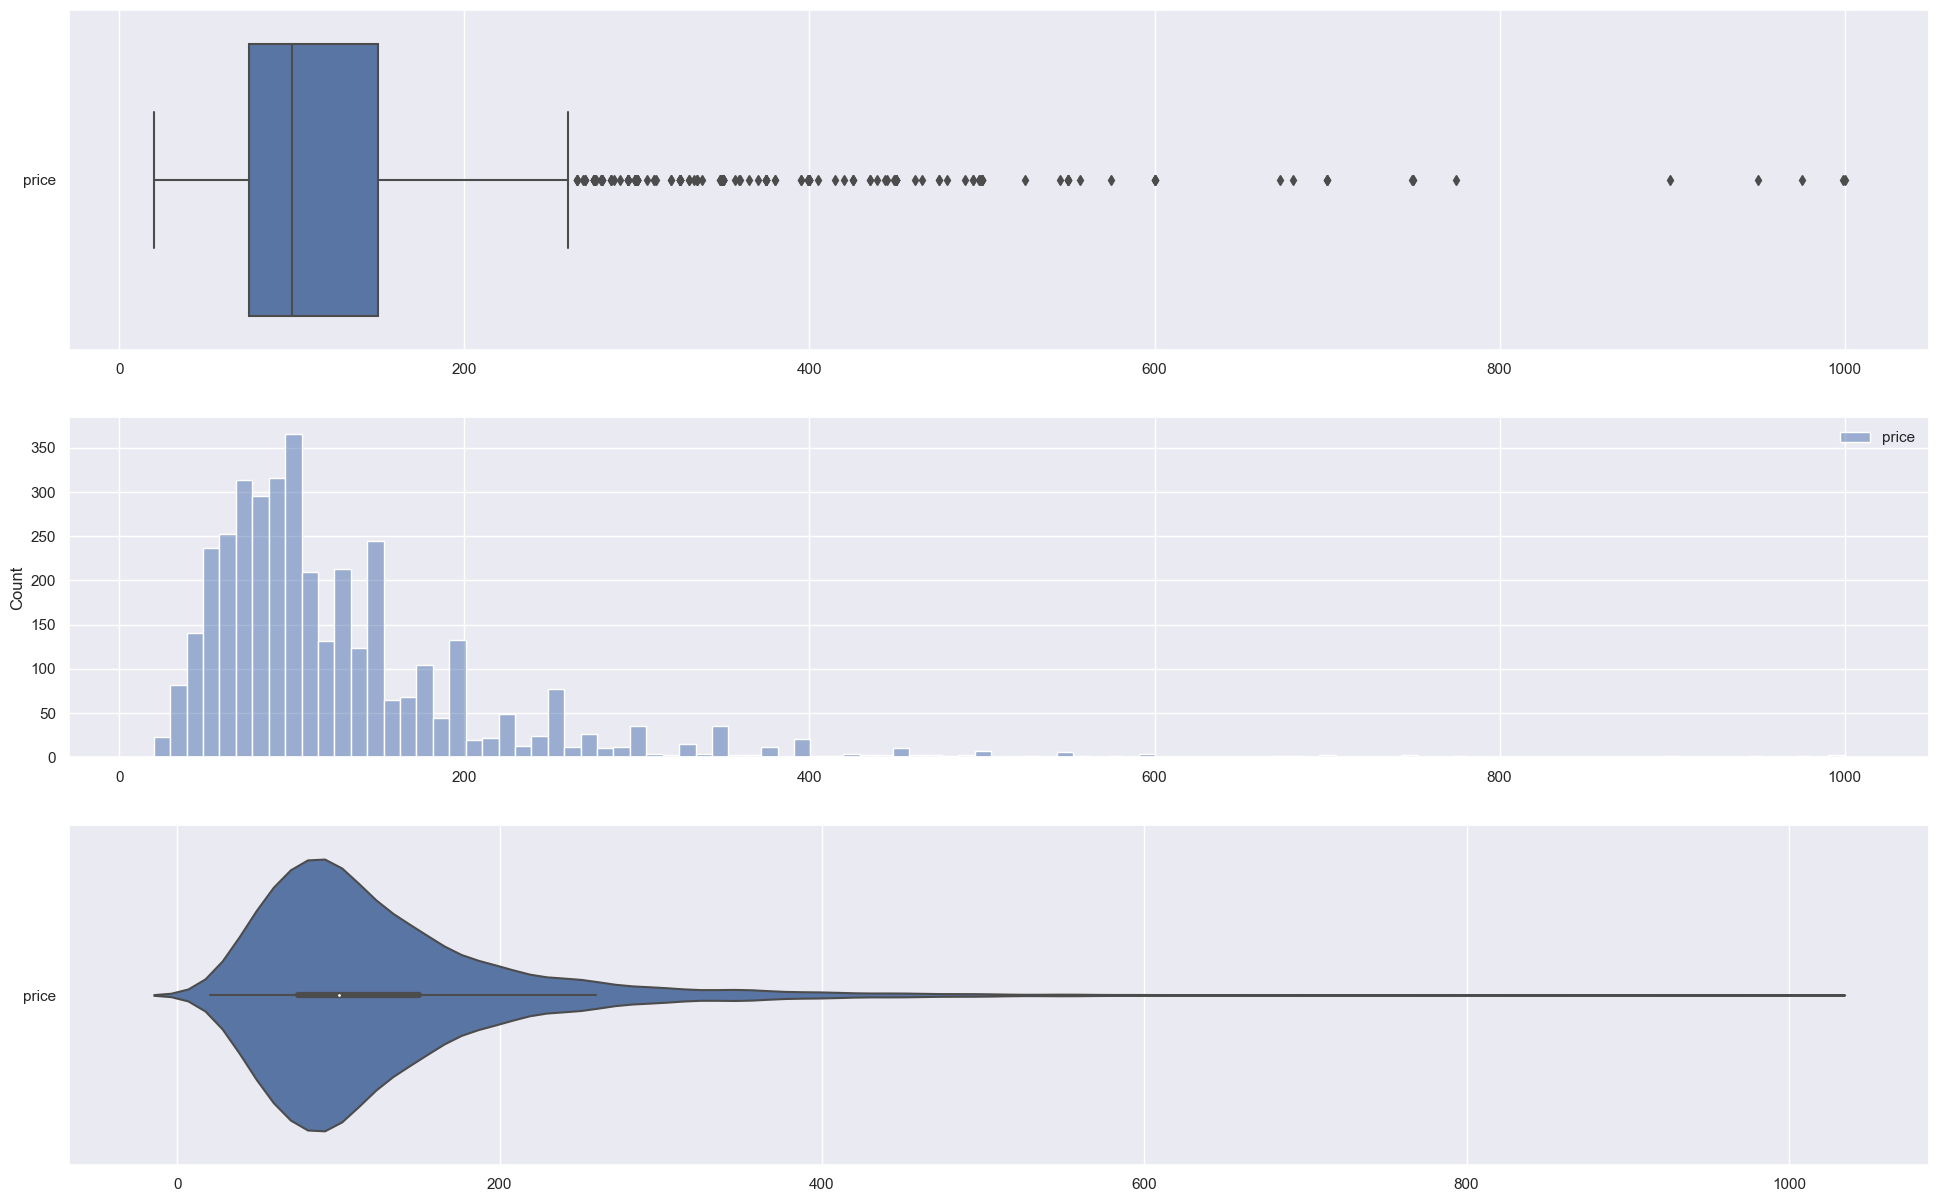

In [783]:
price=pd.DataFrame(listings["price"])
f, axes = plt.subplots(3, 1, figsize=(24, 15))
sb.boxplot(data = price, orient = "h", ax = axes[0])
sb.histplot(data = price, ax = axes[1])
sb.violinplot(data = price, orient = "h", ax = axes[2])

Applying log transformation to "price" to normalise it 

<Axes: ylabel='Density'>

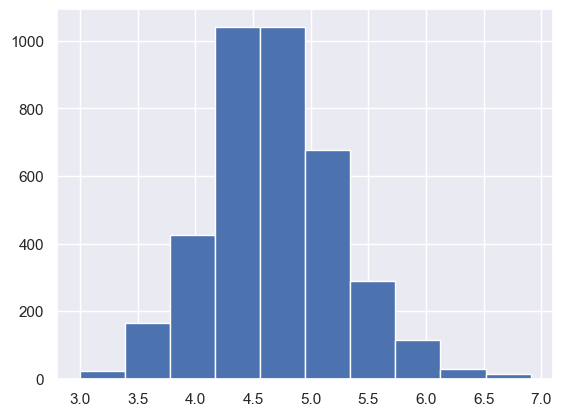

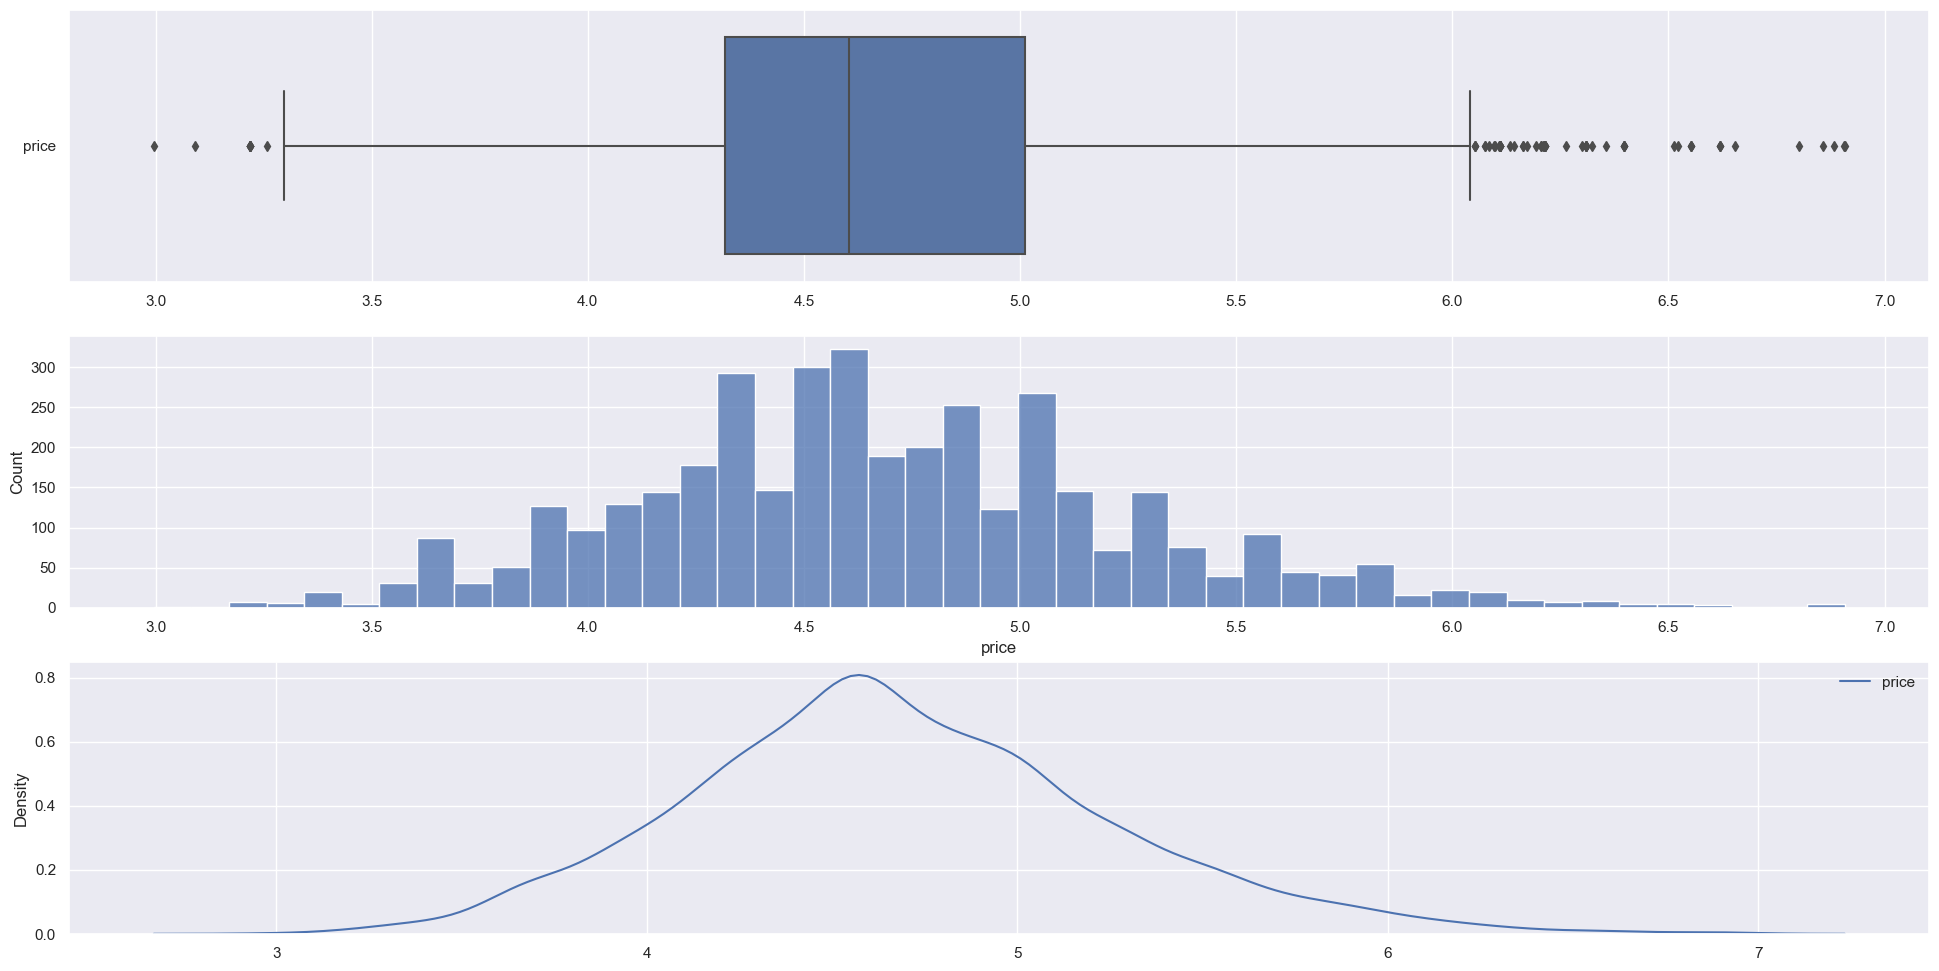

In [784]:
from scipy import stats
plt.hist(stats.boxcox(listings["price"],lmbda=0.0))
listings["price"]=np.log(listings["price"])
f, axes = plt.subplots(3, 1, figsize=(24, 12))
sb.boxplot(data =pd.DataFrame(listings["price"]) , orient = "h", ax = axes[0])
sb.histplot(data = listings["price"], ax = axes[1])
sb.kdeplot(data = pd.DataFrame(listings["price"]),  ax = axes[2])

<Axes: >

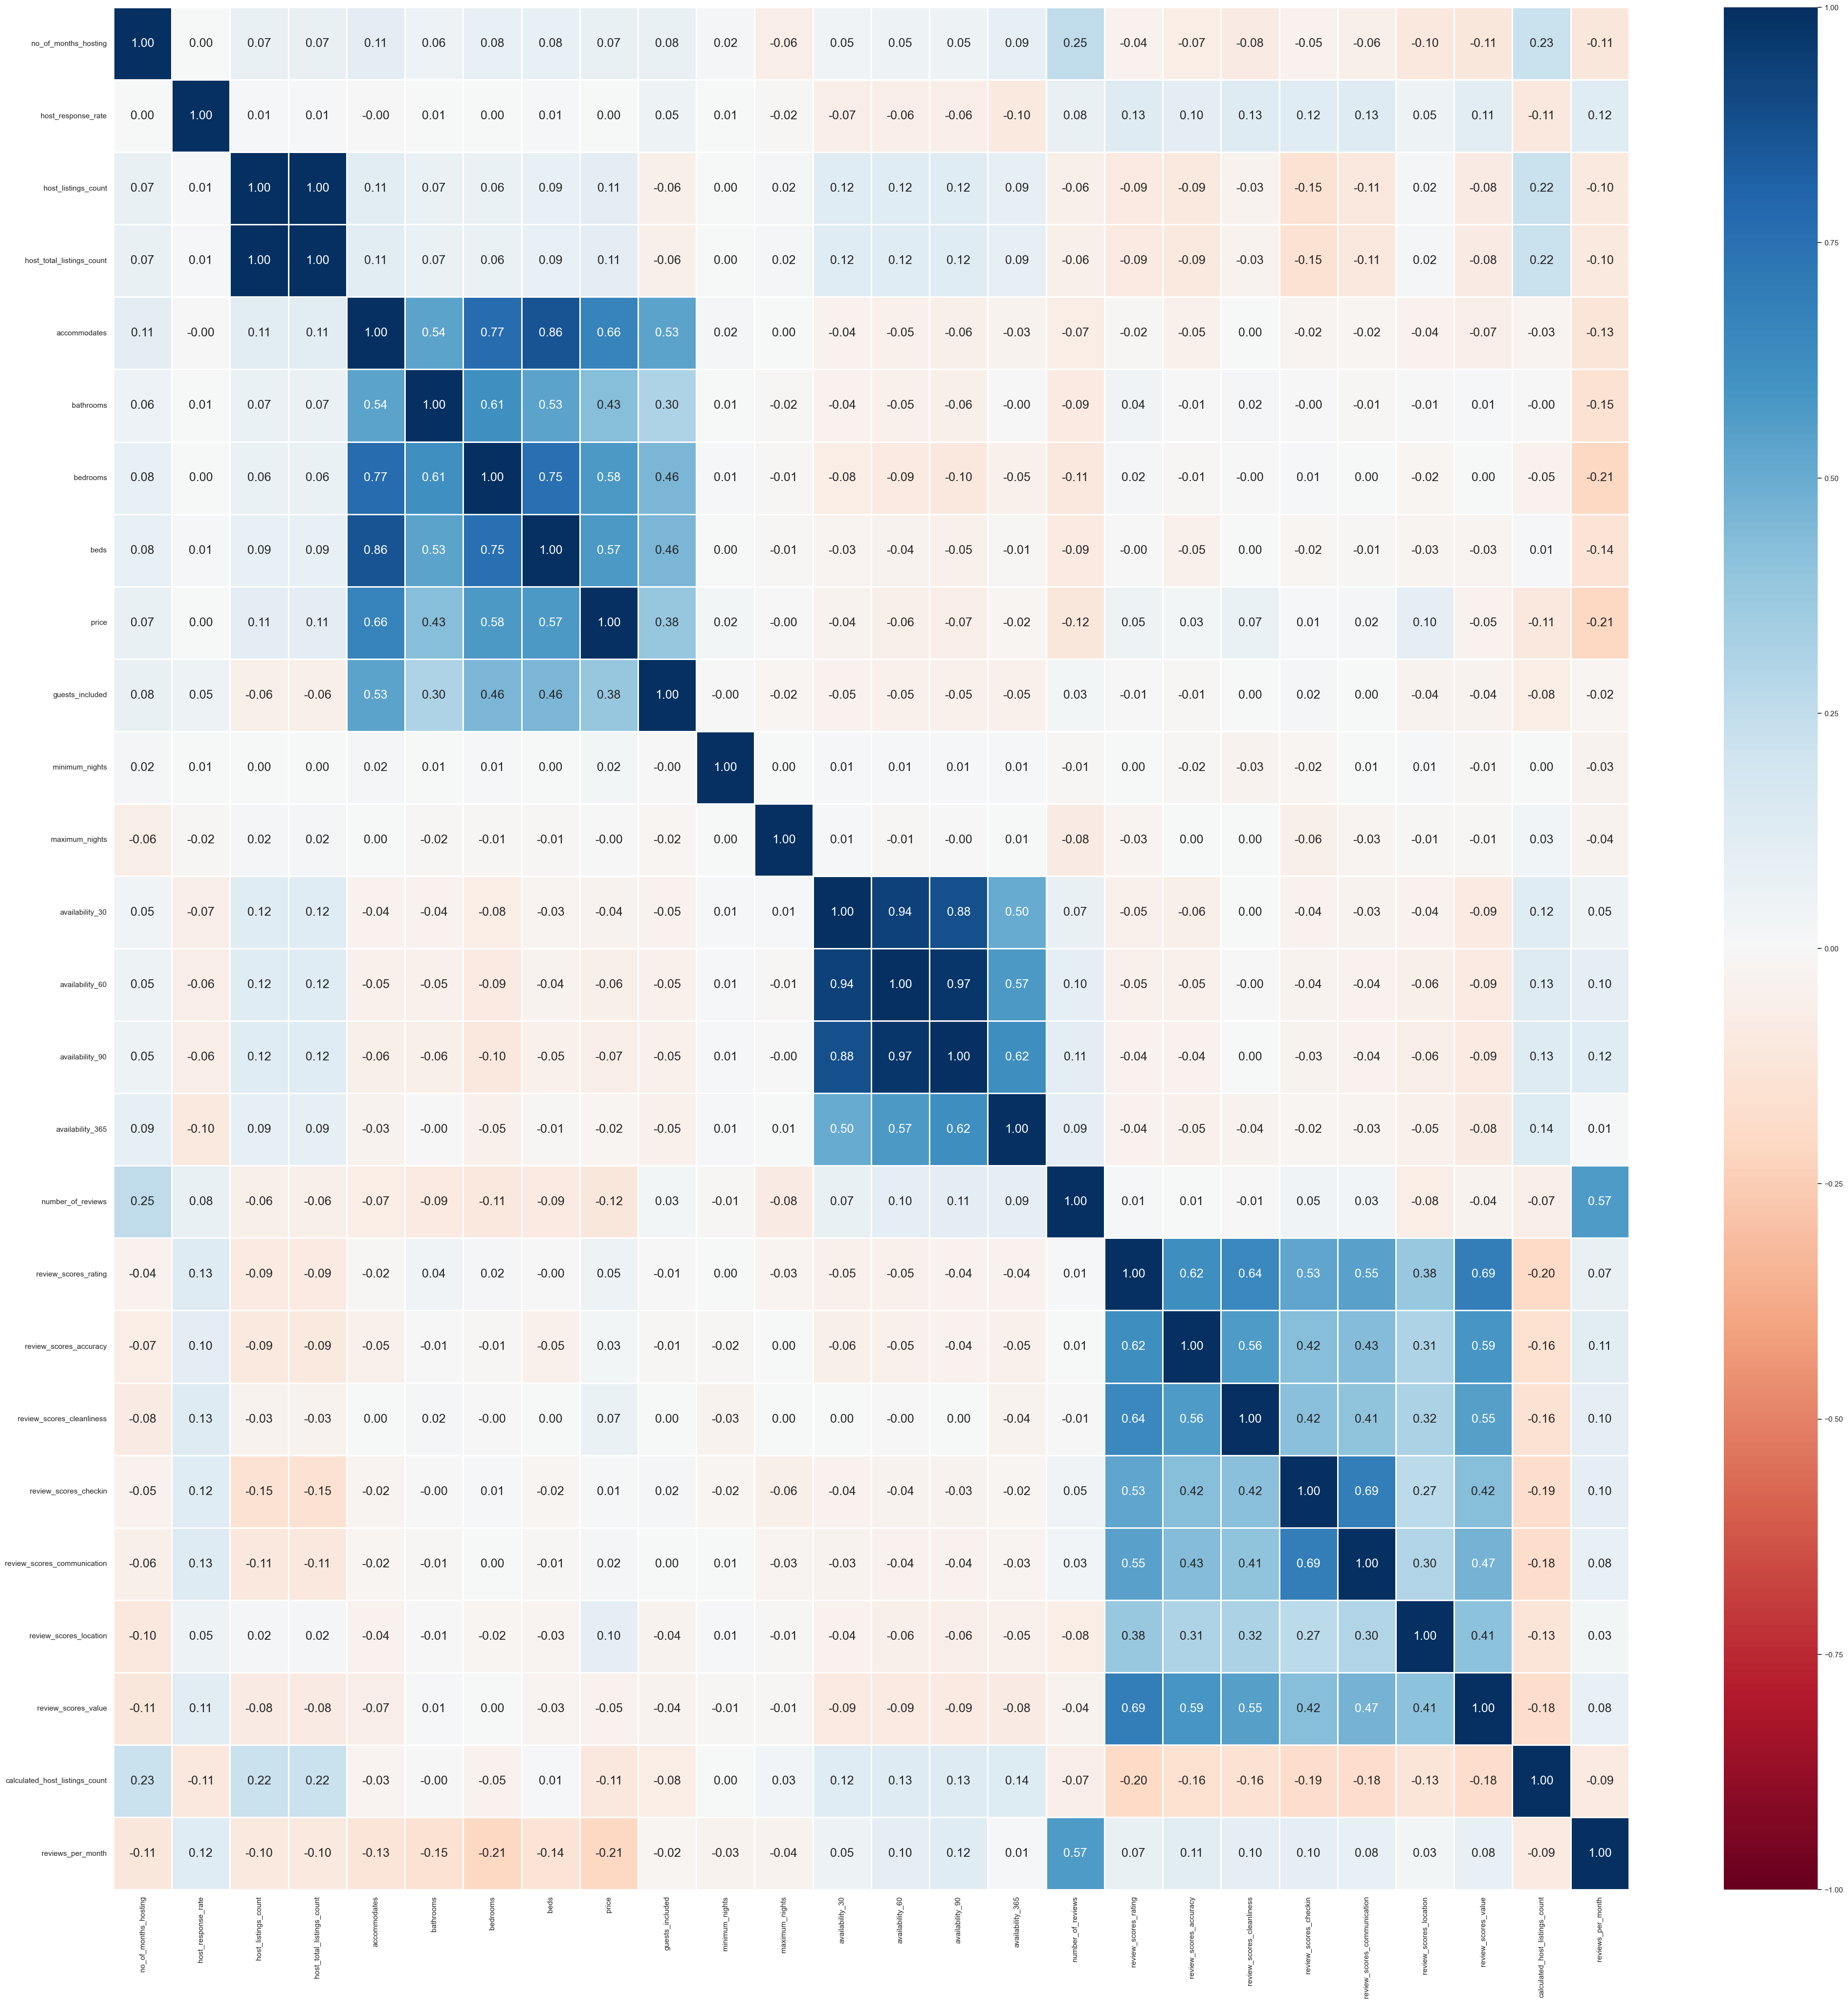

In [785]:
f, axes = plt.subplots(1, 1, figsize=(50, 50))
sb.heatmap(listings.corr(), vmin = -1, vmax = 1, linewidths = 1,
           annot = True, fmt = ".2f", annot_kws = {"size": 18}, cmap = "RdBu")

Keeping only significant numerical features

In [786]:
listings=listings.drop(["calculated_host_listings_count","host_listings_count","host_total_listings_count","availability_30","availability_60","availability_90","availability_365","host_total_listings_count","review_scores_accuracy","review_scores_cleanliness","review_scores_checkin","review_scores_communication","review_scores_location","review_scores_value","minimum_nights","maximum_nights"],axis=1)
listings.info()

<class 'pandas.core.frame.DataFrame'>
Index: 3818 entries, 8354452 to 10267360
Data columns (total 11 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   no_of_months_hosting  3818 non-null   int64  
 1   host_response_rate    3818 non-null   float64
 2   accommodates          3818 non-null   int64  
 3   bathrooms             3818 non-null   float64
 4   bedrooms              3818 non-null   float64
 5   beds                  3818 non-null   float64
 6   price                 3818 non-null   float64
 7   guests_included       3818 non-null   int64  
 8   number_of_reviews     3818 non-null   int64  
 9   review_scores_rating  3818 non-null   float64
 10  reviews_per_month     3818 non-null   float64
dtypes: float64(7), int64(4)
memory usage: 357.9 KB


<Axes: >

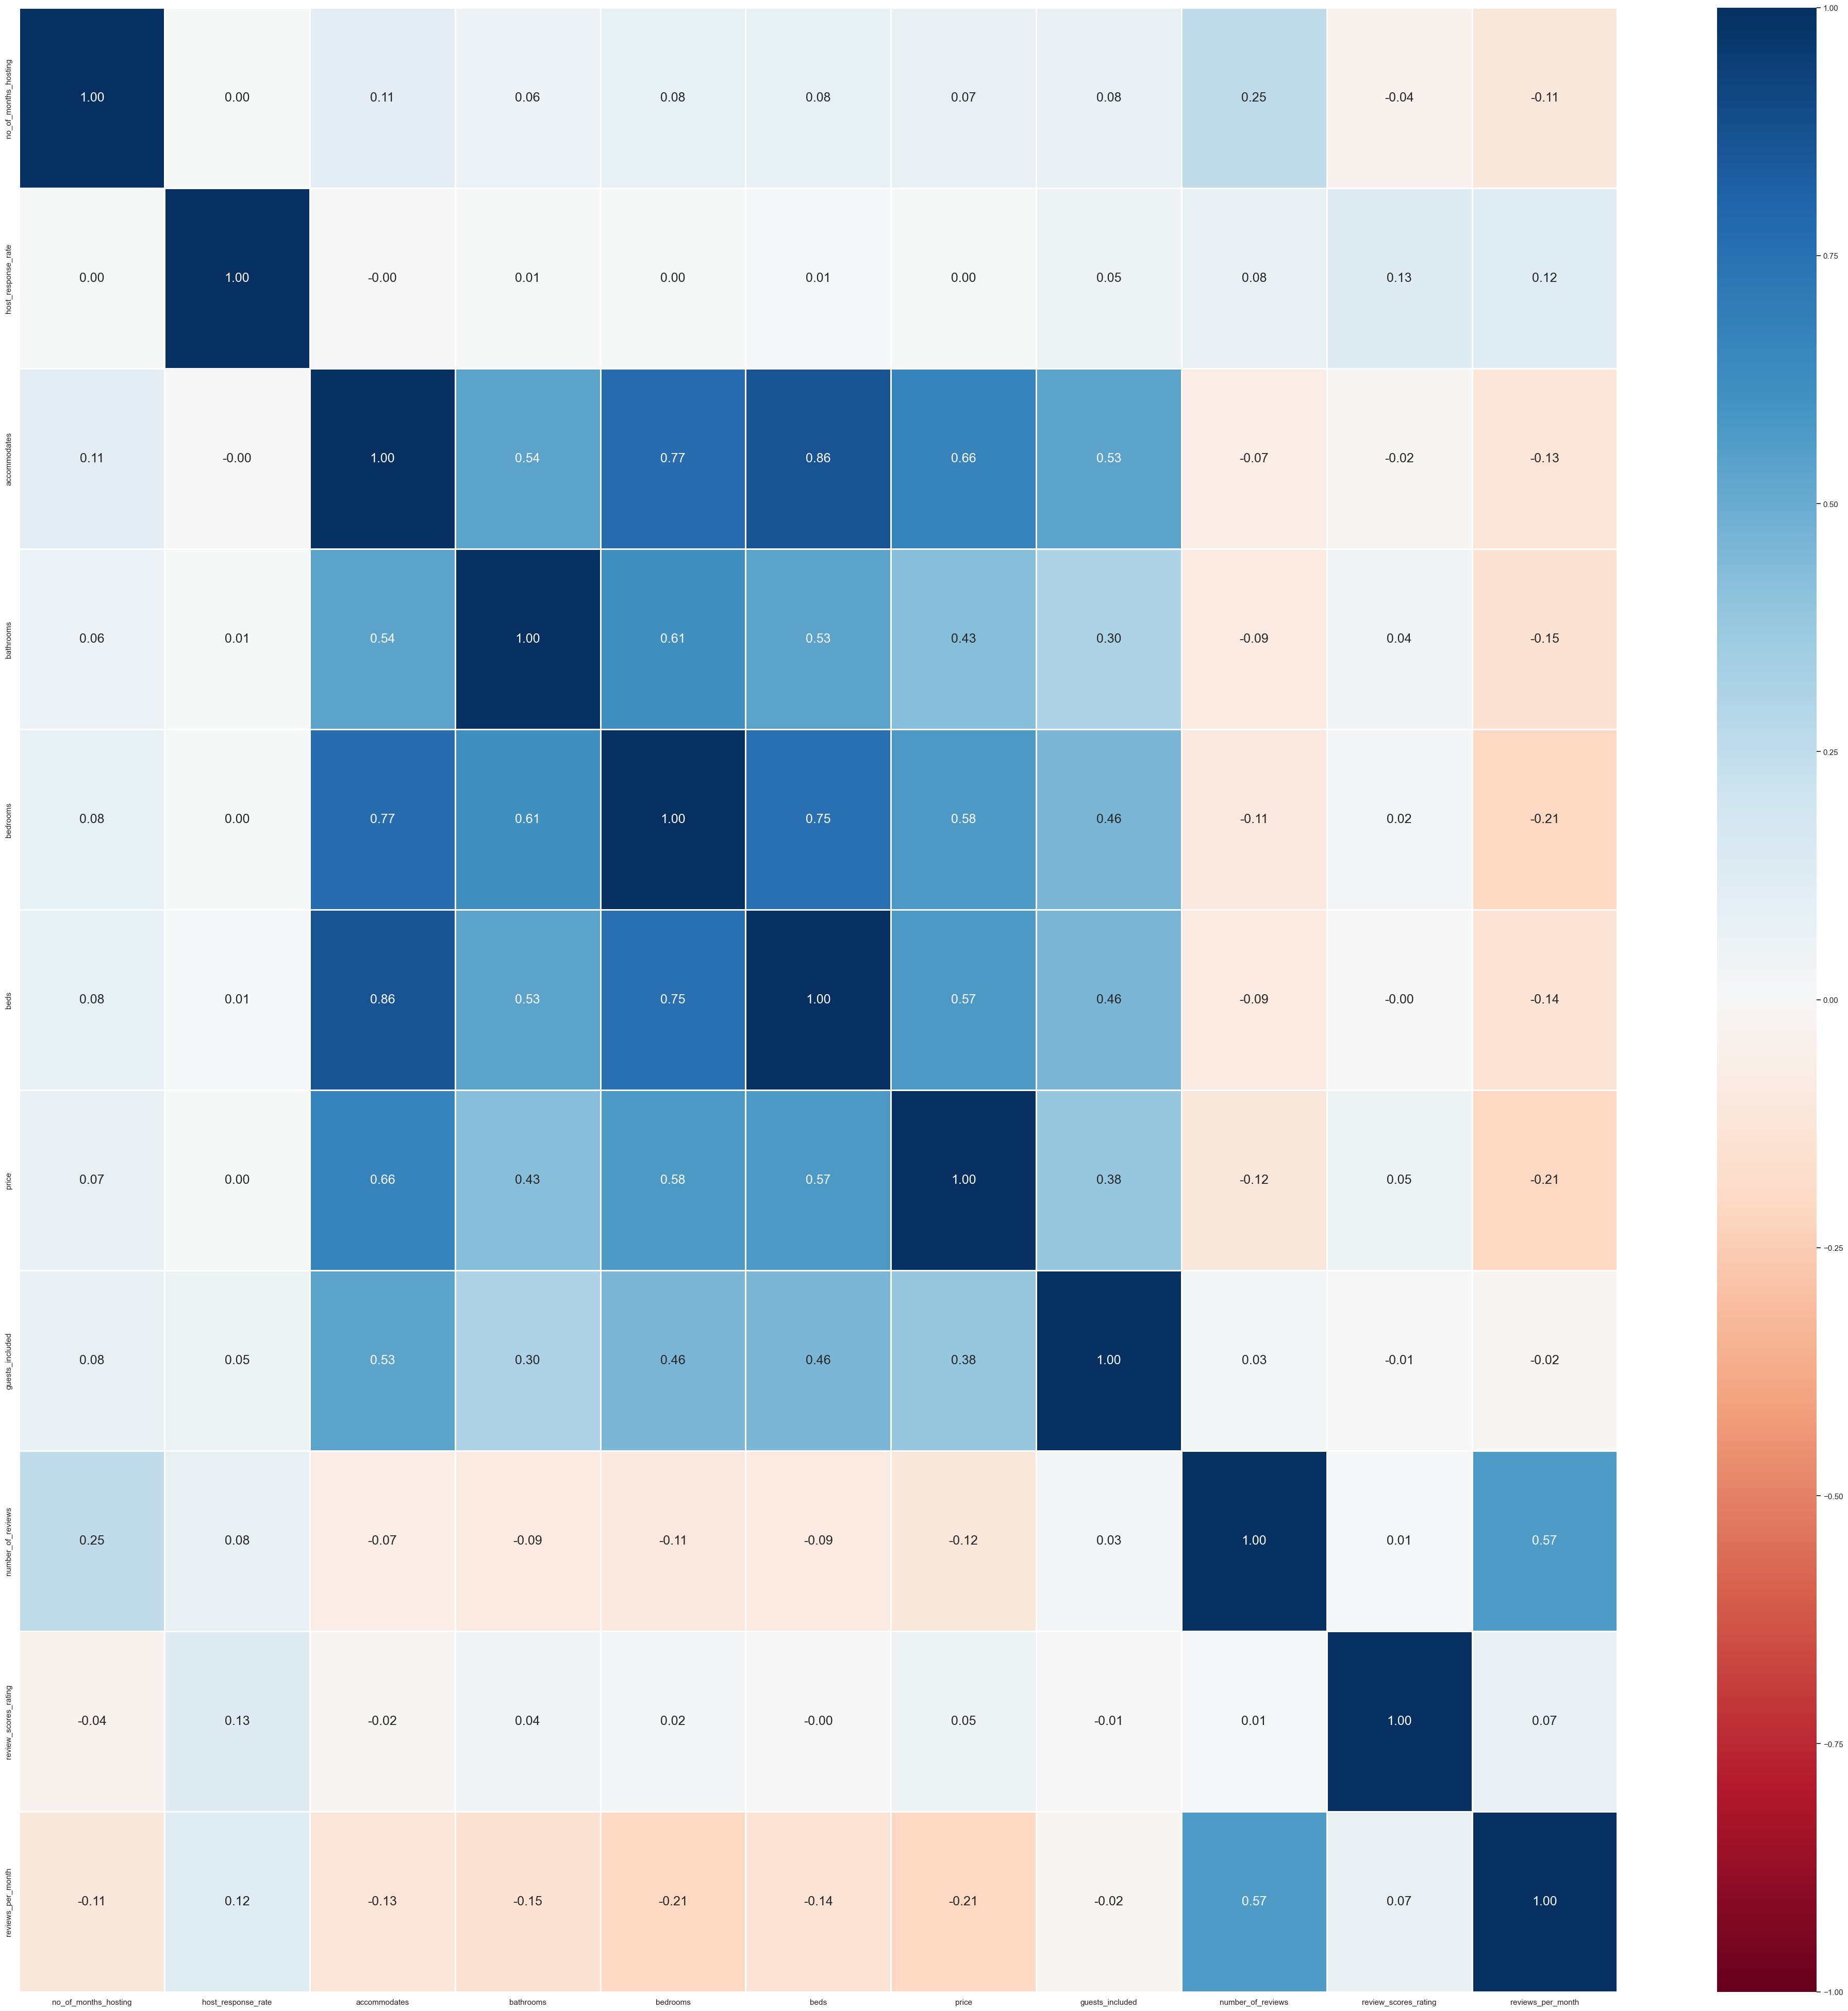

In [787]:
f, axes = plt.subplots(1, 1, figsize=(50, 50))
sb.heatmap(listings.corr(), vmin = -1, vmax = 1, linewidths = 1,
           annot = True, fmt = ".2f", annot_kws = {"size": 18}, cmap = "RdBu")

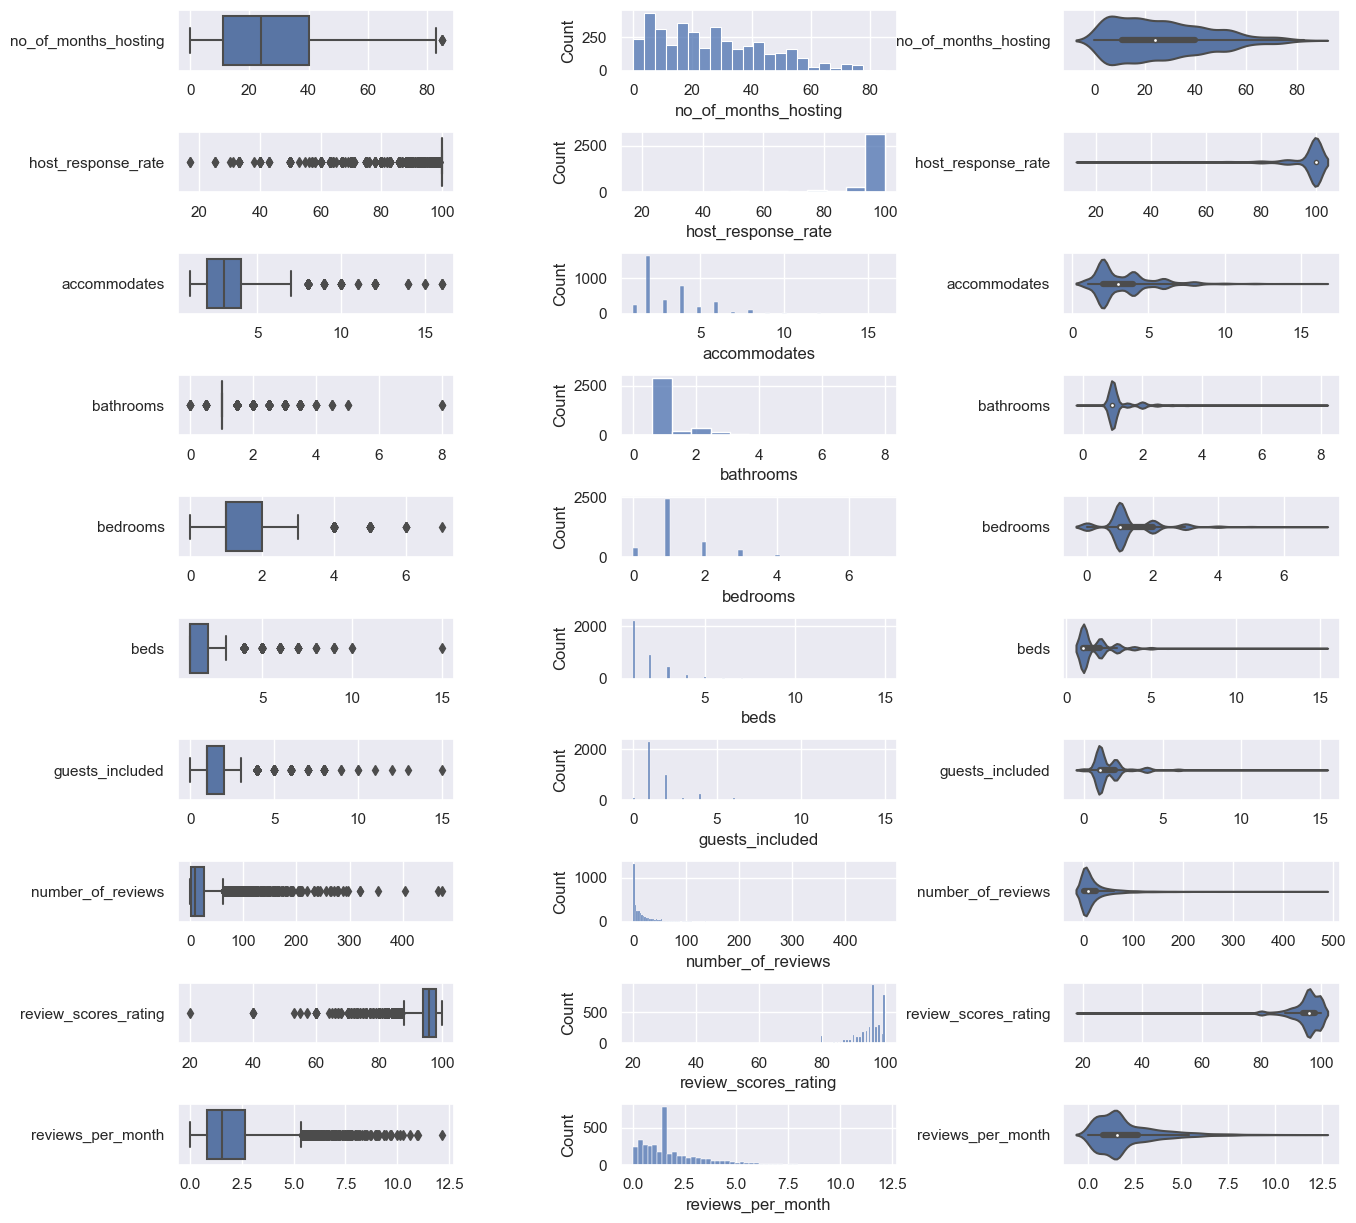

In [788]:
f, axes = plt.subplots(10, 3, figsize=(15,15))
f.subplots_adjust(hspace=1, wspace=0.6)  # Adjust the spacing between subplots

count = 0
for var in listings:
    if var!="price":
        sb.boxplot(data = pd.DataFrame(listings[var]), orient = "h", ax = axes[count,0])
        sb.histplot(data = listings[var], ax = axes[count,1])
        sb.violinplot(data = pd.DataFrame(listings[var]), orient = "h", ax = axes[count,2])
        count += 1

C:\Users\linsh\AppData\Local\Programs\Python\Python311\Lib\site-packages\seaborn\axisgrid.py:118: UserWarning: The figure layout has changed to tight
  self._figure.tight_layout(*args, **kwargs)


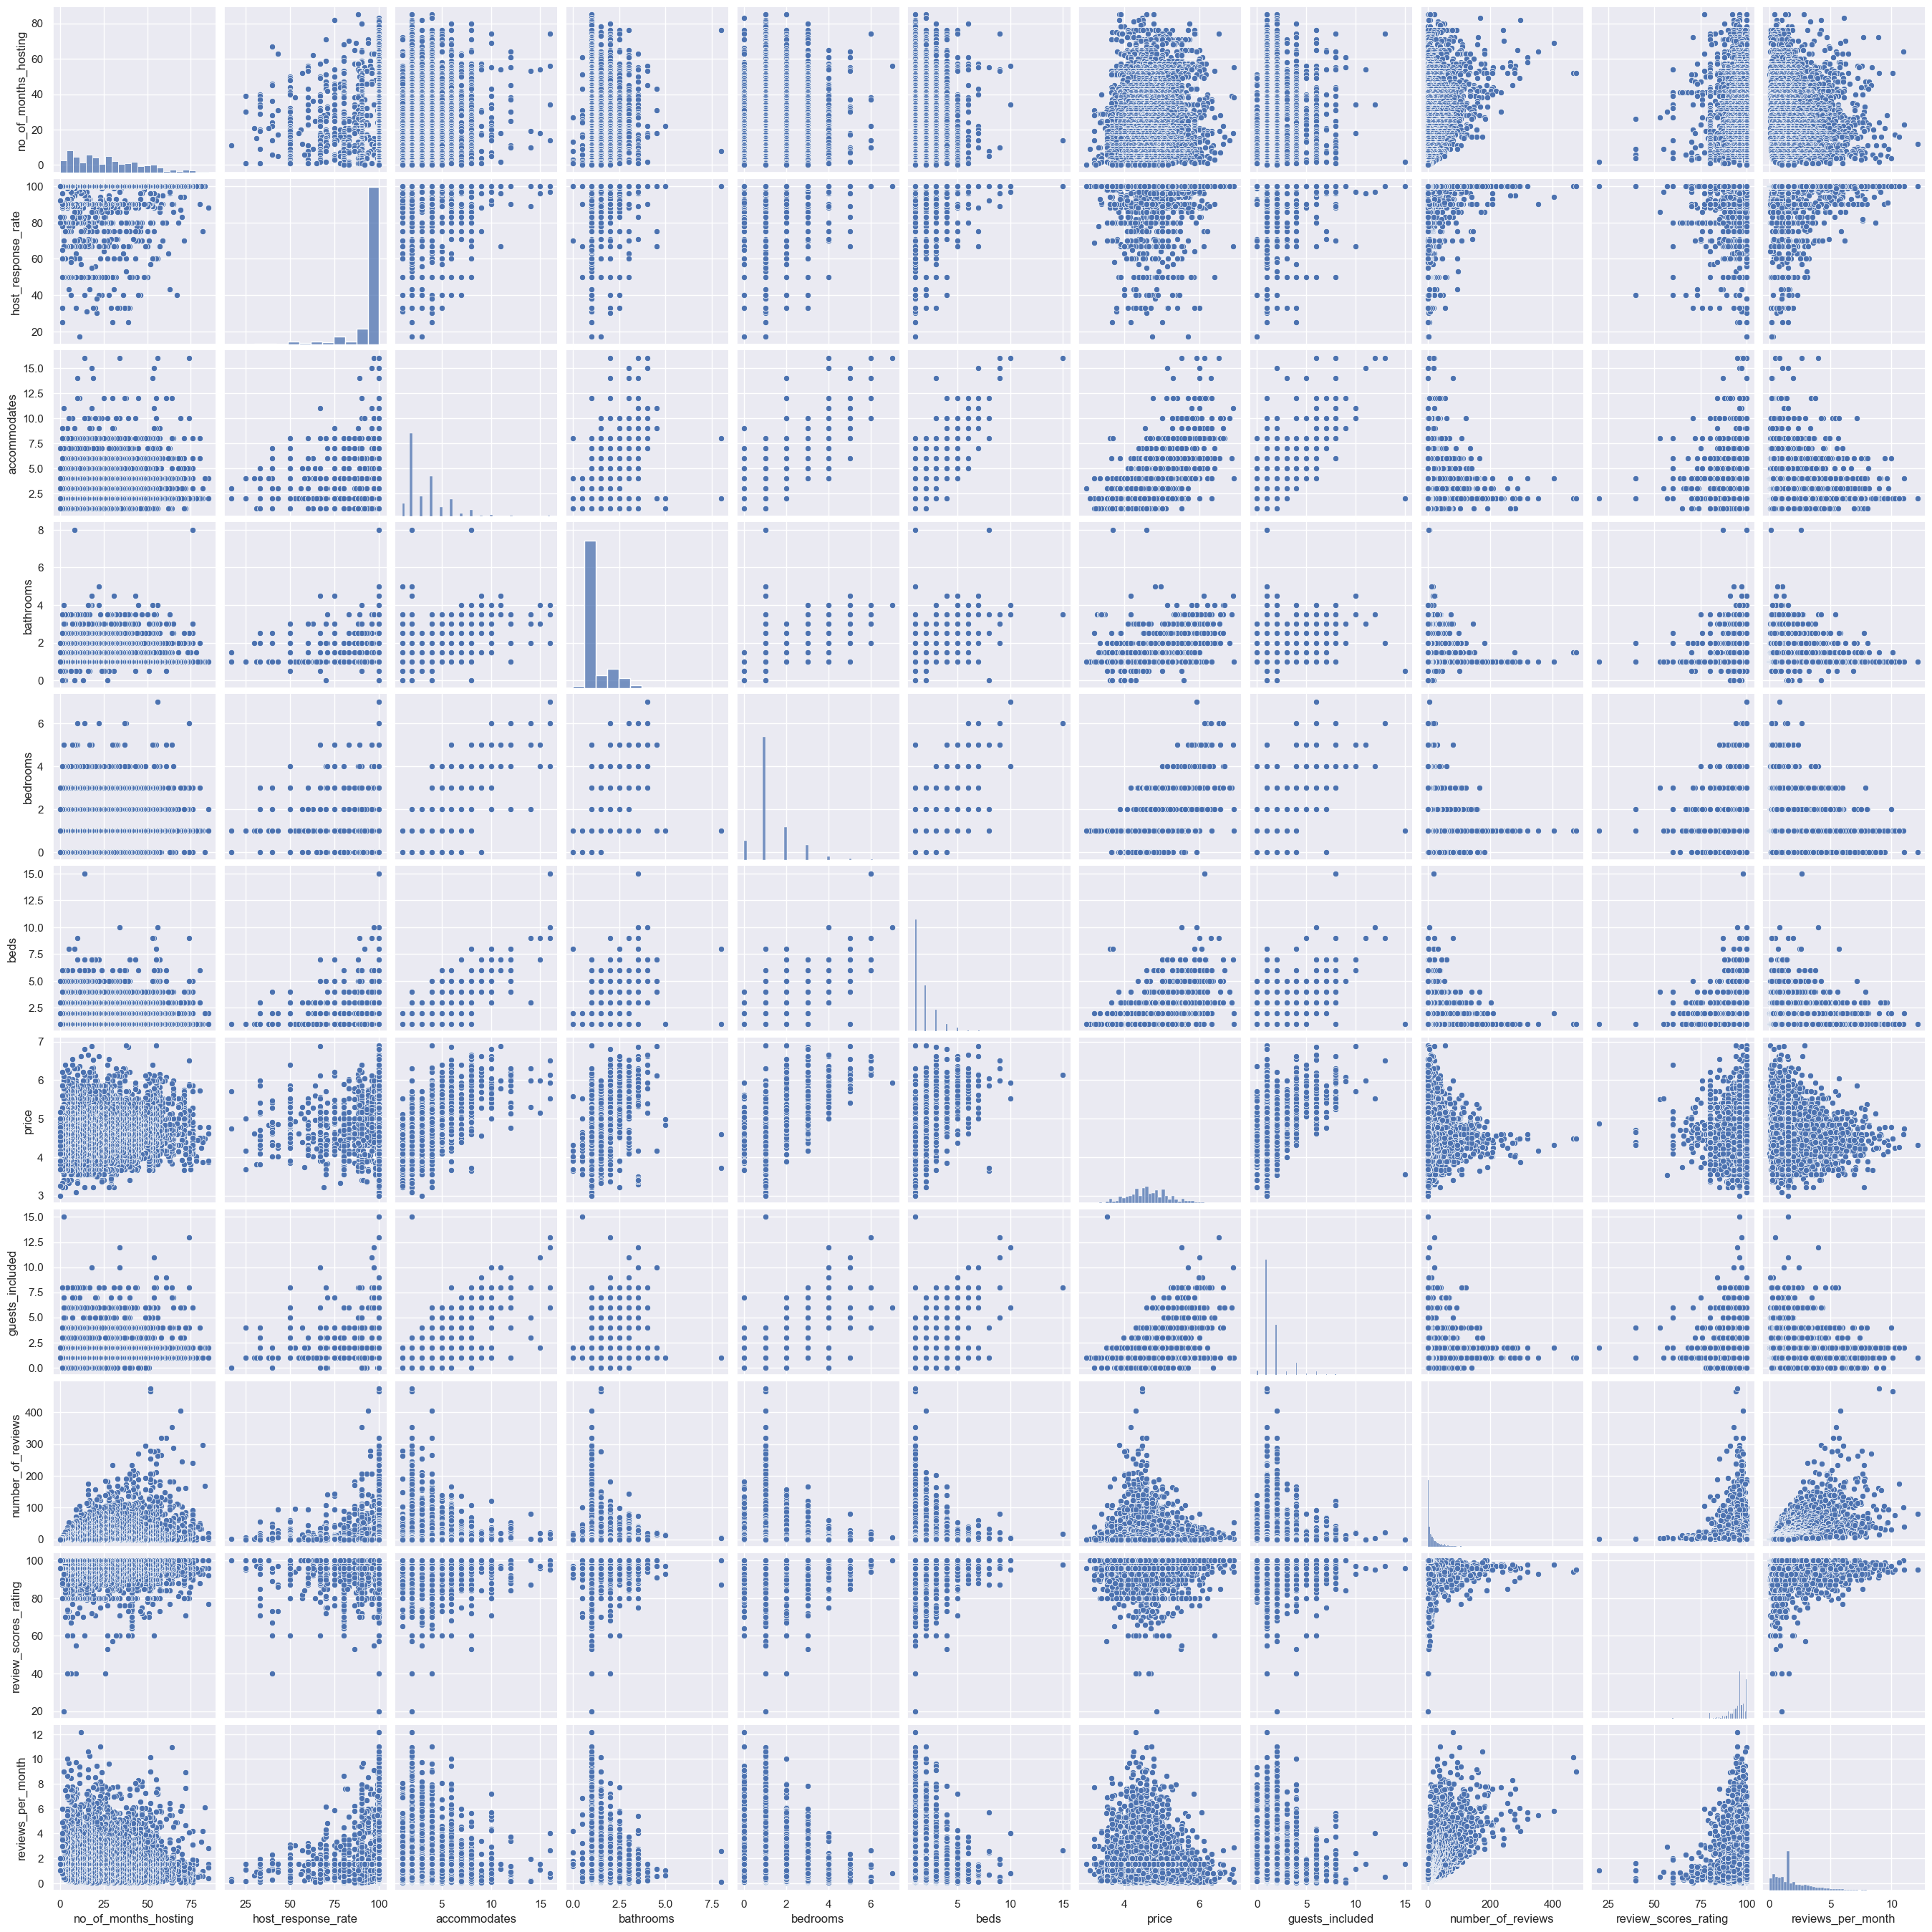

In [789]:
sb.pairplot(data = listings)

Exploration of categorical features 

In [704]:
listings_csv["property_type"].value_counts()

property_type
House              1733
Apartment          1708
Townhouse           118
Condominium          91
Loft                 40
Bed & Breakfast      37
Other                22
Cabin                21
Camper/RV            13
Bungalow             13
Boat                  8
Tent                  5
Treehouse             3
Chalet                2
Dorm                  2
Yurt                  1
Name: count, dtype: int64

In [705]:
listings_csv["neighbourhood_cleansed"].value_counts()

neighbourhood_cleansed
Broadway             397
Belltown             234
Wallingford          167
Fremont              158
Minor                135
                    ... 
Arbor Heights          5
Pinehurst              4
South Beacon Hill      4
South Park             3
Roxhill                2
Name: count, Length: 87, dtype: int64

In [706]:
listings_csv["room_type"].value_counts()

room_type
Entire home/apt    2541
Private room       1160
Shared room         117
Name: count, dtype: int64

In [707]:
listings_csv["bed_type"].value_counts()

bed_type
Real Bed         3657
Futon              74
Pull-out Sofa      47
Airbed             27
Couch              13
Name: count, dtype: int64

In [708]:
listings_csv["cancellation_policy"].value_counts()

cancellation_policy
strict      1417
moderate    1251
flexible    1150
Name: count, dtype: int64

In [709]:
temp=pd.DataFrame(listings_csv[["property_type","neighbourhood_cleansed","room_type","bed_type","cancellation_policy"]])
temp.index = listings_csv["id"] 
temp = temp.astype('category')
temp.isnull().sum()

property_type             1
neighbourhood_cleansed    0
room_type                 0
bed_type                  0
cancellation_policy       0
dtype: int64

In [710]:
temp_clean=temp.copy()
temp_clean=temp_clean.replace(r'^\s*$', np.nan, regex=True)
temp_clean["neighbourhood_cleansed"].fillna(temp["neighbourhood_cleansed"].mode()[0],inplace=True) 
temp_clean["property_type"].fillna(temp["property_type"].mode()[0],inplace=True) 
temp_clean.info()

<class 'pandas.core.frame.DataFrame'>
Index: 3818 entries, 8354452 to 10267360
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype   
---  ------                  --------------  -----   
 0   property_type           3818 non-null   category
 1   neighbourhood_cleansed  3818 non-null   category
 2   room_type               3818 non-null   category
 3   bed_type                3818 non-null   category
 4   cancellation_policy     3818 non-null   category
dtypes: category(5)
memory usage: 52.3 KB


<Axes: xlabel='price', ylabel='property_type'>

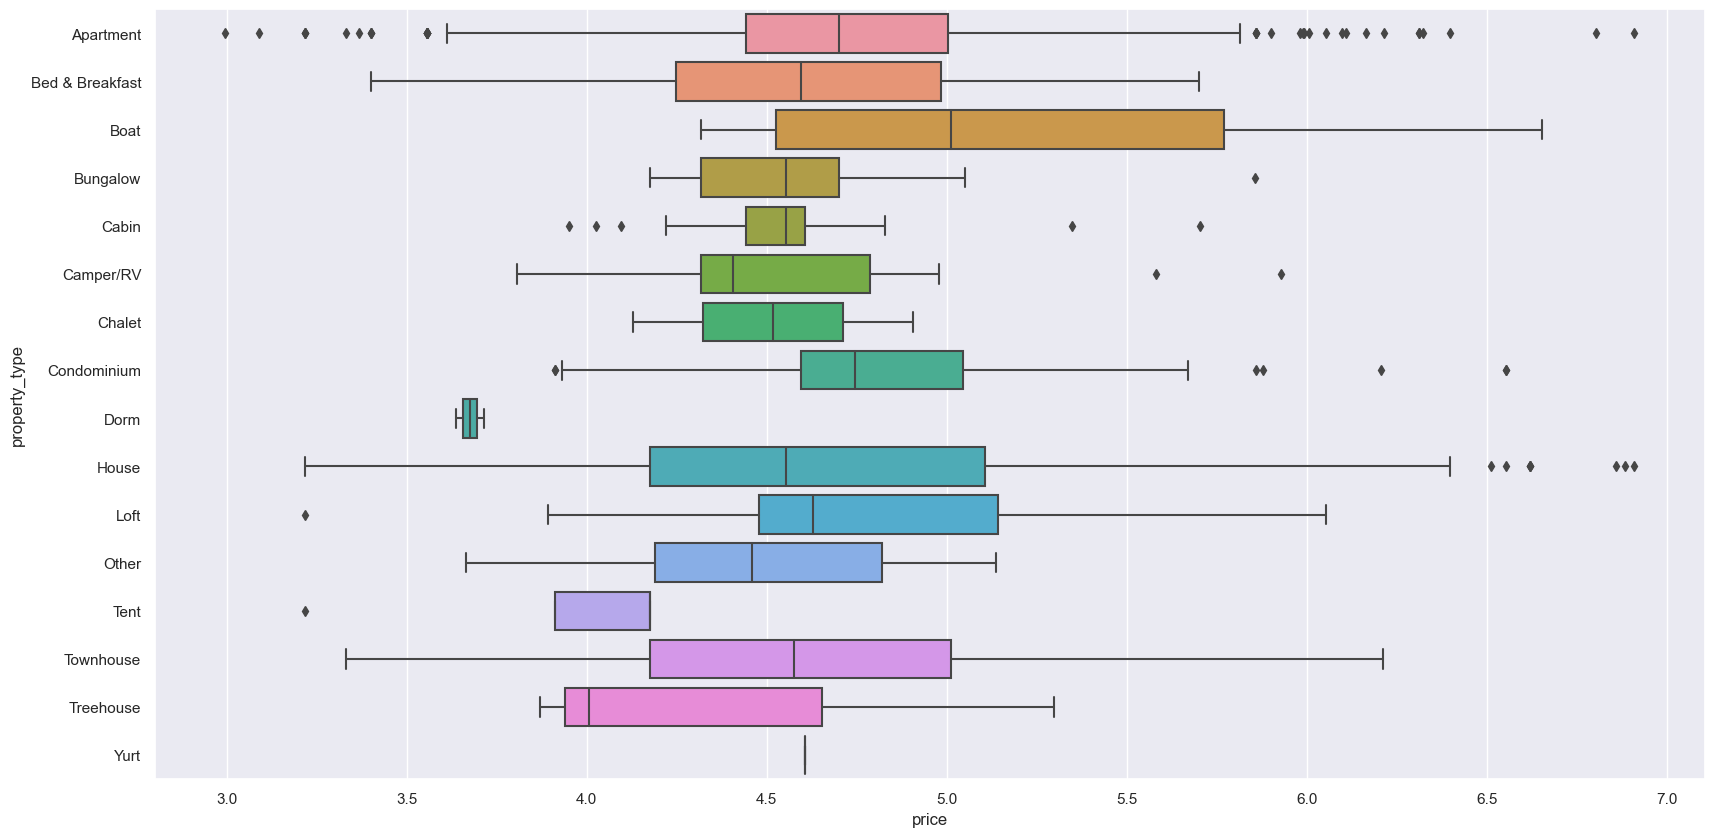

In [711]:
joint_temp= pd.concat([listings["price"], temp], axis = 1).reindex(temp.index)
f = plt.figure(figsize=(20, 10))
sb.boxplot(x = "price", y = "property_type", data = joint_temp, orient = "h")

<Axes: xlabel='price', ylabel='neighbourhood_cleansed'>

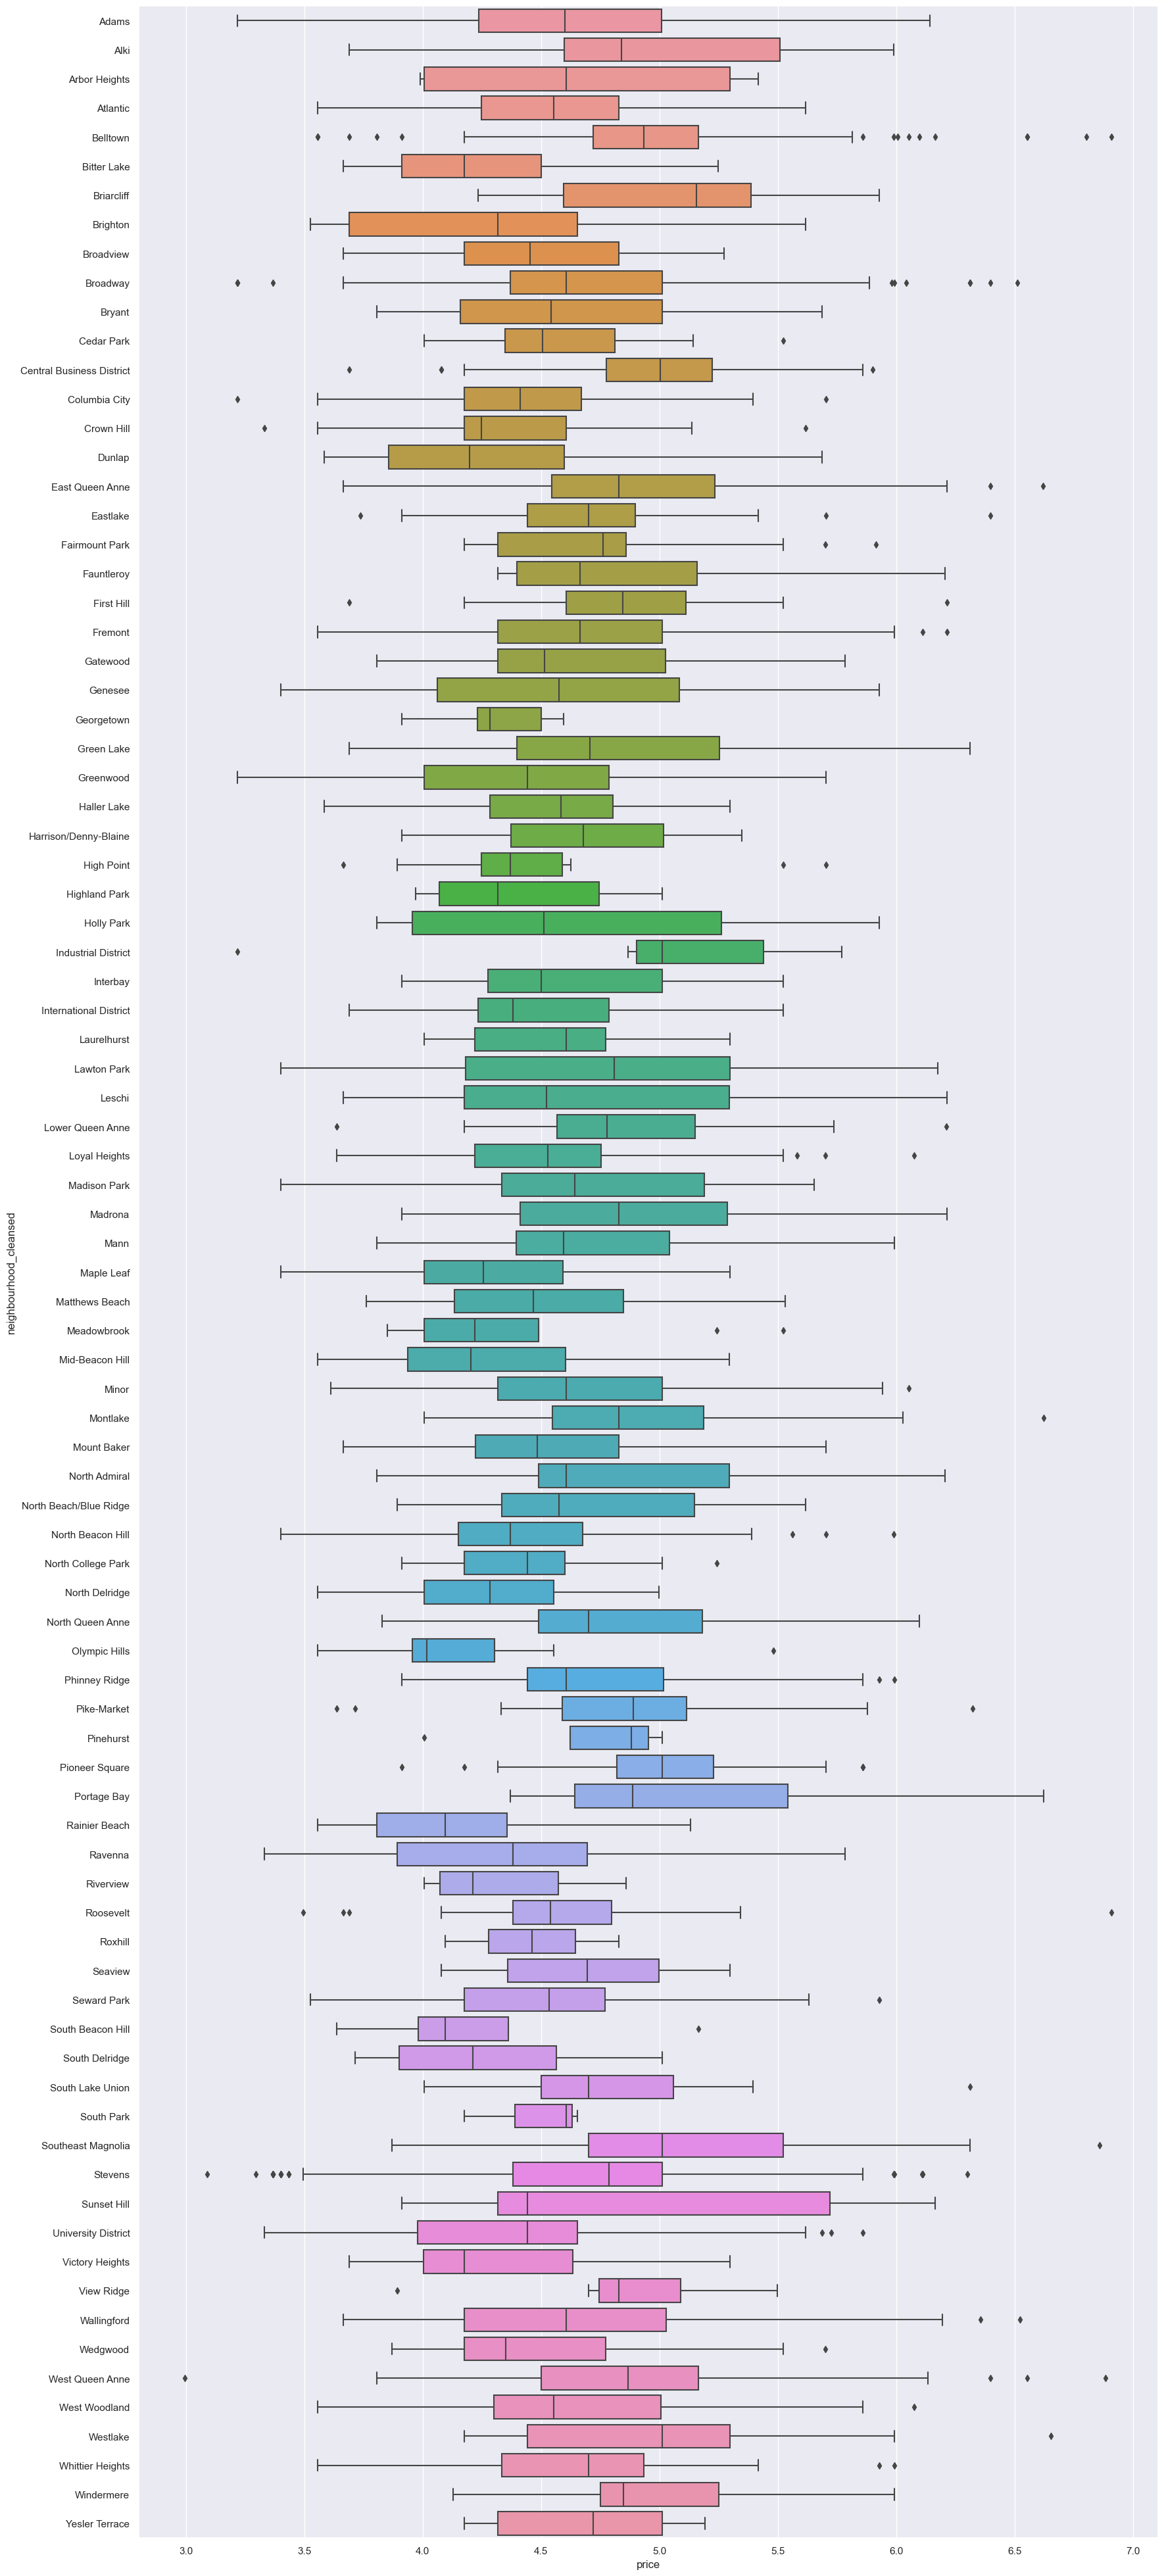

In [712]:
f = plt.figure(figsize=(20, 50))
sb.boxplot(x = "price", y = "neighbourhood_cleansed", data = joint_temp, orient = "h")

<Axes: xlabel='price', ylabel='room_type'>

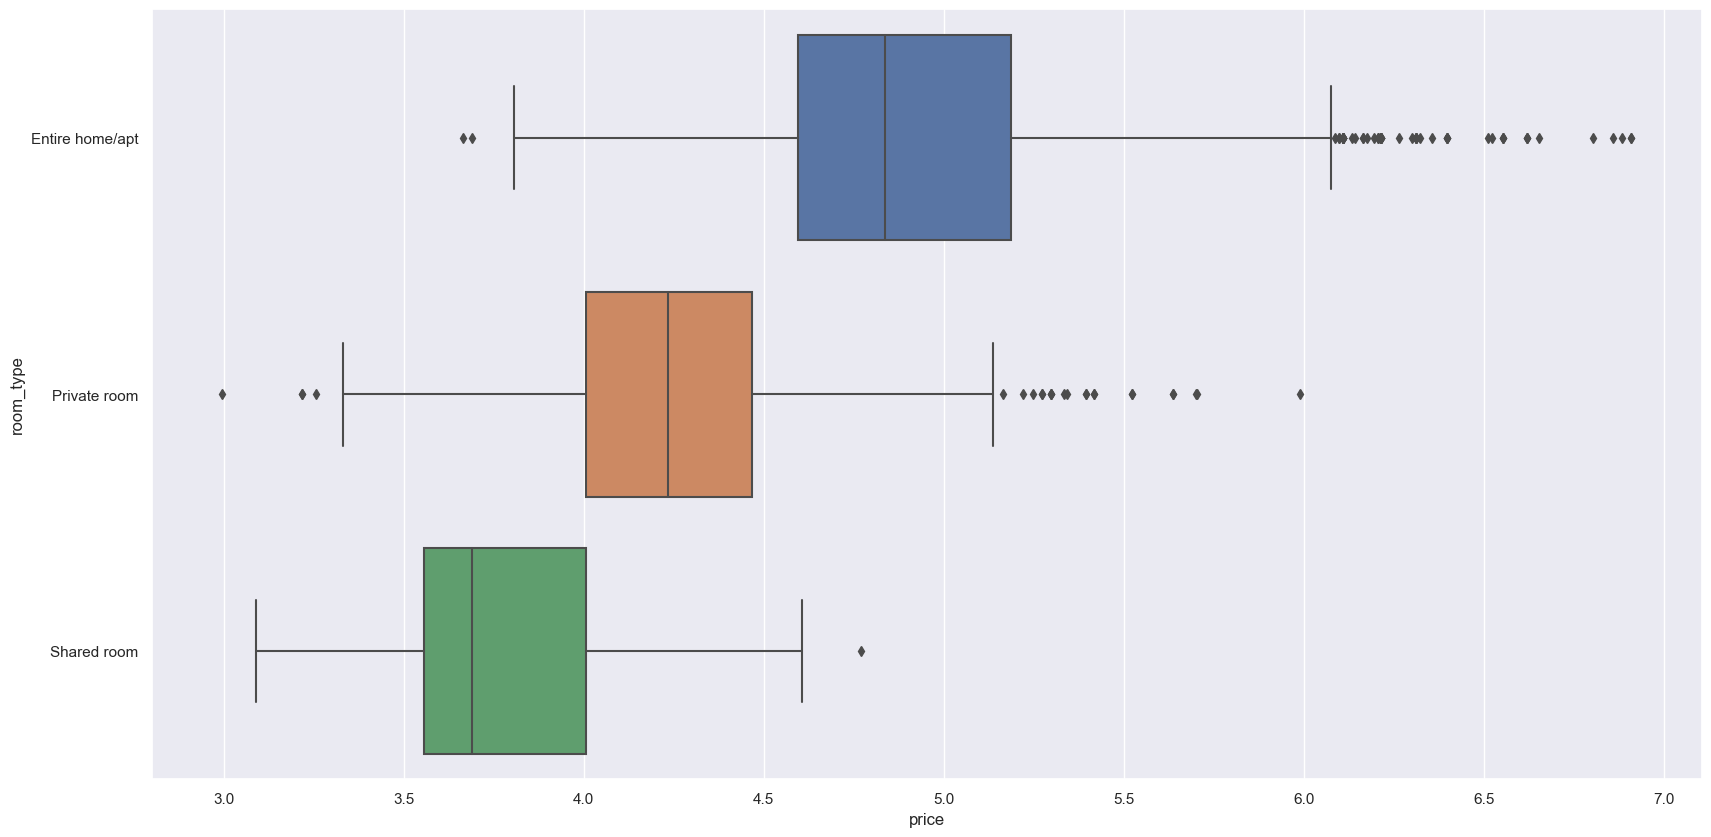

In [713]:
f = plt.figure(figsize=(20, 10))
sb.boxplot(x = "price", y = "room_type", data = joint_temp, orient = "h")

<Axes: xlabel='price', ylabel='cancellation_policy'>

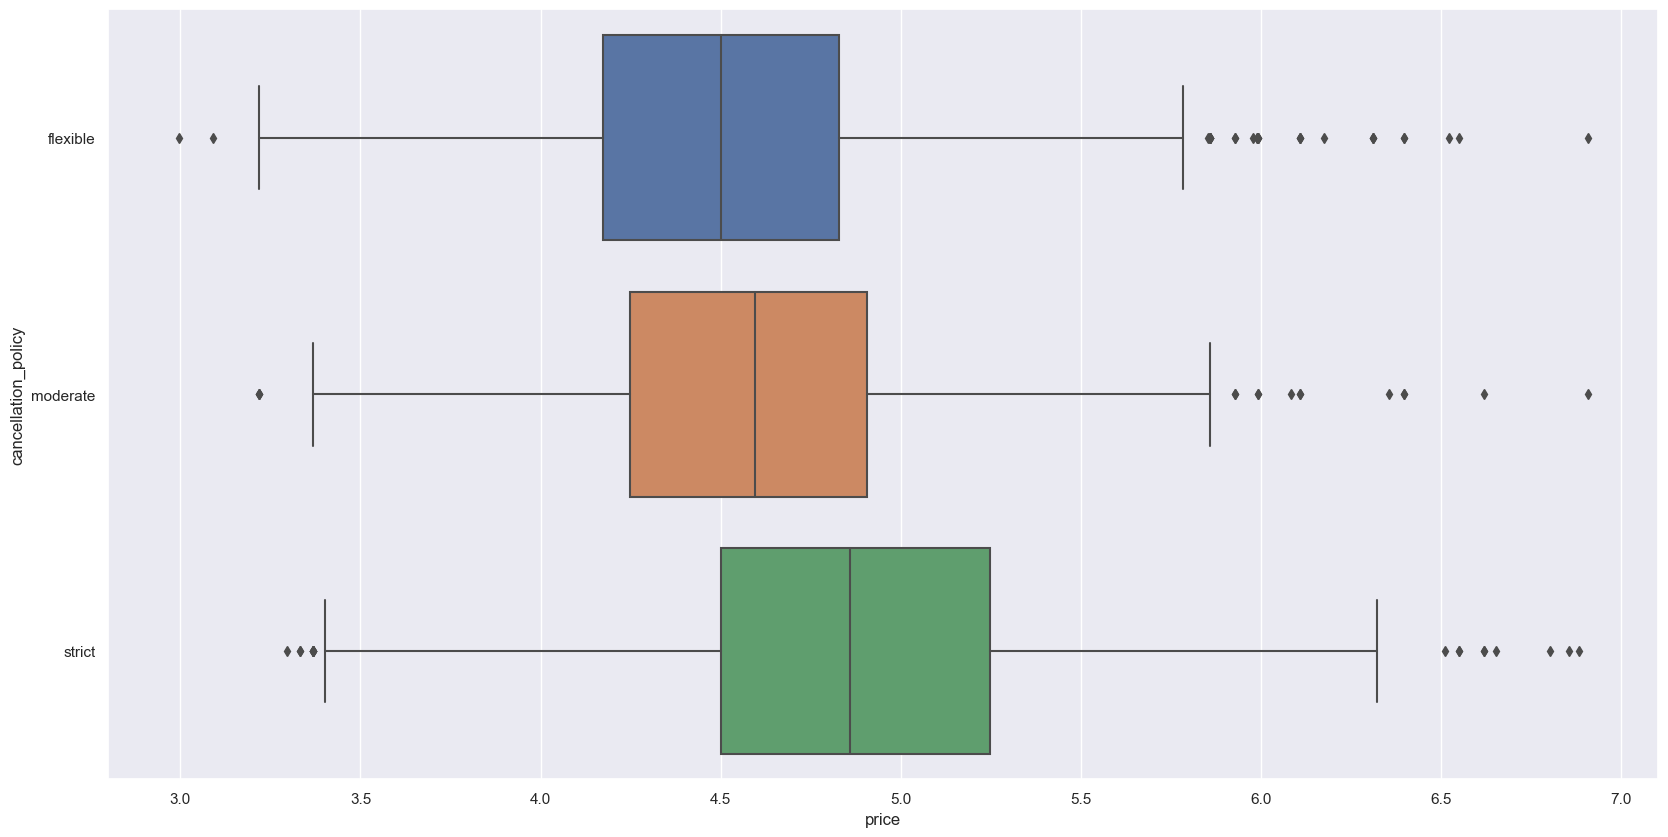

In [714]:
f = plt.figure(figsize=(20, 10))
sb.boxplot(x = "price", y = "cancellation_policy", data = joint_temp, orient = "h")

<Axes: xlabel='price', ylabel='bed_type'>

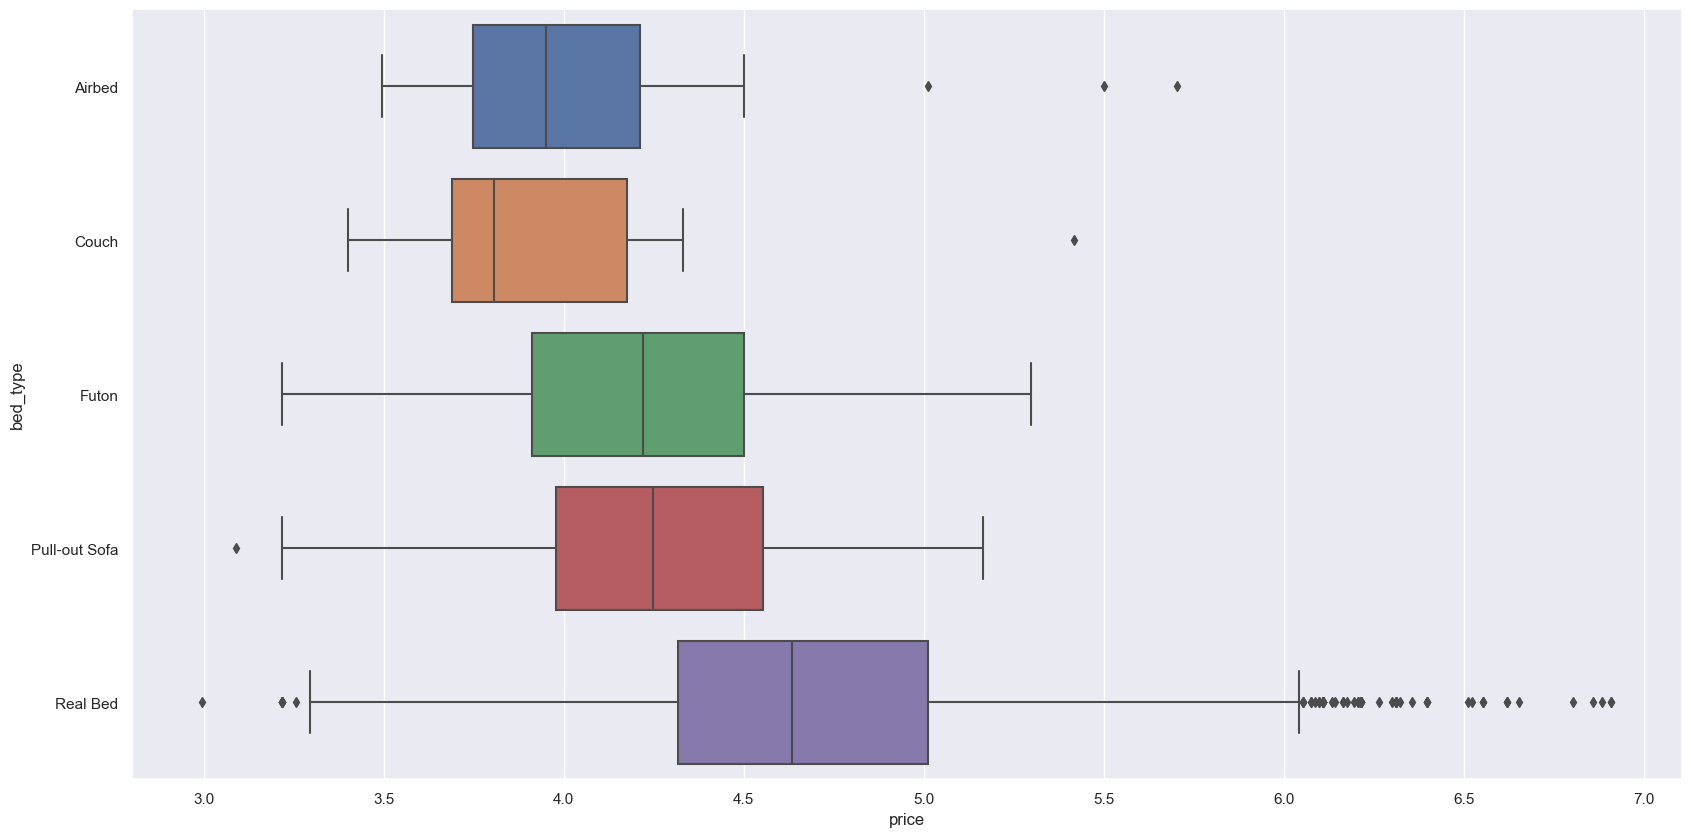

In [715]:
f = plt.figure(figsize=(20, 10))
sb.boxplot(x = "price", y = "bed_type", data = joint_temp, orient = "h")

Encoding the chosen categorical values 

In [716]:
temp1= pd.get_dummies(temp_clean, columns=["room_type"])
temp2=pd.get_dummies(temp_clean, columns=["bed_type"])
listings=pd.concat([listings, temp1], axis = 1).reindex(listings.index)
listings=pd.concat([listings, temp2], axis = 1).reindex(listings.index)
listings=listings.drop(["property_type","bed_type_Airbed","room_type","bed_type","neighbourhood_cleansed","cancellation_policy","room_type_Shared room"],axis=1)               
 

In [717]:
listings.info()

<class 'pandas.core.frame.DataFrame'>
Index: 3818 entries, 8354452 to 10267360
Data columns (total 17 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   no_of_months_hosting       3818 non-null   int64  
 1   host_response_rate         3818 non-null   float64
 2   accommodates               3818 non-null   int64  
 3   bathrooms                  3818 non-null   float64
 4   bedrooms                   3818 non-null   float64
 5   beds                       3818 non-null   float64
 6   price                      3818 non-null   float64
 7   guests_included            3818 non-null   int64  
 8   number_of_reviews          3818 non-null   int64  
 9   review_scores_rating       3818 non-null   float64
 10  reviews_per_month          3818 non-null   float64
 11  room_type_Entire home/apt  3818 non-null   bool   
 12  room_type_Private room     3818 non-null   bool   
 13  bed_type_Couch             3818 non-null   

In [718]:
y=pd.DataFrame(listings["price"])
X=listings.drop(["price"],axis=1)

In [719]:
X.head(10)

,no_of_months_hosting,host_response_rate,accommodates,bathrooms,bedrooms,beds,guests_included,number_of_reviews,review_scores_rating,reviews_per_month,room_type_Entire home/apt,room_type_Private room,bed_type_Couch,bed_type_Futon,bed_type_Pull-out Sofa,bed_type_Real Bed
id,,,,,,,,,,,,,,,,
8354452,24,100.0,2,1.0,0.0,1.0,1,0,96.0,1.54,True,False,False,False,False,True
10235014,24,100.0,2,1.0,1.0,1.0,1,0,96.0,1.54,True,False,False,False,False,True
3335,85,88.0,4,1.0,2.0,2.0,2,0,96.0,1.54,True,False,False,False,False,True
6117473,85,88.0,2,1.0,1.0,1.0,1,20,92.0,2.84,False,True,False,False,False,True
7745016,85,88.0,2,1.0,1.0,1.0,1,2,100.0,0.42,False,True,False,False,False,True
1263470,85,88.0,2,1.0,1.0,1.0,2,6,77.0,1.27,True,False,False,False,False,True
1707064,83,100.0,4,1.0,0.0,2.0,2,168,96.0,6.09,True,False,False,False,False,True
5682,82,100.0,2,1.0,1.0,1.0,1,297,96.0,4.21,True,False,False,False,False,True
6836330,82,75.0,3,1.0,1.0,1.0,2,6,93.0,0.99,True,False,False,False,False,True


In [720]:
y.head(10)

,price
id,
8354452,4.595120
10235014,5.521461
3335,4.787492
6117473,3.871201
7745016,3.912023
1263470,4.605170
1707064,4.488636
5682,3.871201
6836330,4.499810


Split data into train and test set

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.3,random_state=42)
RFreg=RandomForestRegressor(n_estimators=600,min_samples_leaf=20,criterion="friedman_mse",max_features="sqrt",min_samples_split= 5,max_depth= 20,random_state=42)

In [722]:
RFreg.fit(X_train,y_train.values.ravel())
y_train_pred=RFreg.predict(X_train)
y_test_pred=RFreg.predict(X_test)

In [723]:
# Check the Goodness of Fit (on Train Data)
print()
print("Goodness of Fit of Model \tTrain Dataset")
print("Explained Variance (R^2) \t:", RFreg.score(X_train, y_train))
print("Mean Squared Error (MSE) \t:", mean_squared_error(y_train, y_train_pred))
print()

# Check the Goodness of Fit (on Test Data)
print("Goodness of Fit of Model \tTest Dataset")
print("Explained Variance (R^2) \t:",RFreg.score(X_test, y_test))
print("Mean Squared Error (MSE) \t:", mean_squared_error(y_test, y_test_pred))
print()


Goodness of Fit of Model 	Train Dataset
Explained Variance (R^2) 	: 0.650436666167071
Mean Squared Error (MSE) 	: 0.005024663168142402

Goodness of Fit of Model 	Test Dataset
Explained Variance (R^2) 	: 0.6399091208539054
Mean Squared Error (MSE) 	: 0.005336594511428547



Cross validate results 

In [724]:
from sklearn.model_selection import KFold,cross_val_score
from sklearn.metrics import make_scorer, explained_variance_score
kf = KFold(n_splits = 5,random_state=42,shuffle=True)

scores = cross_val_score(RFreg, X_test, y_test.values.ravel(), cv=kf, 
                         scoring=make_scorer(explained_variance_score))
print("Mean explained variance: %.2f" % scores.mean())


Mean explained variance: 0.61


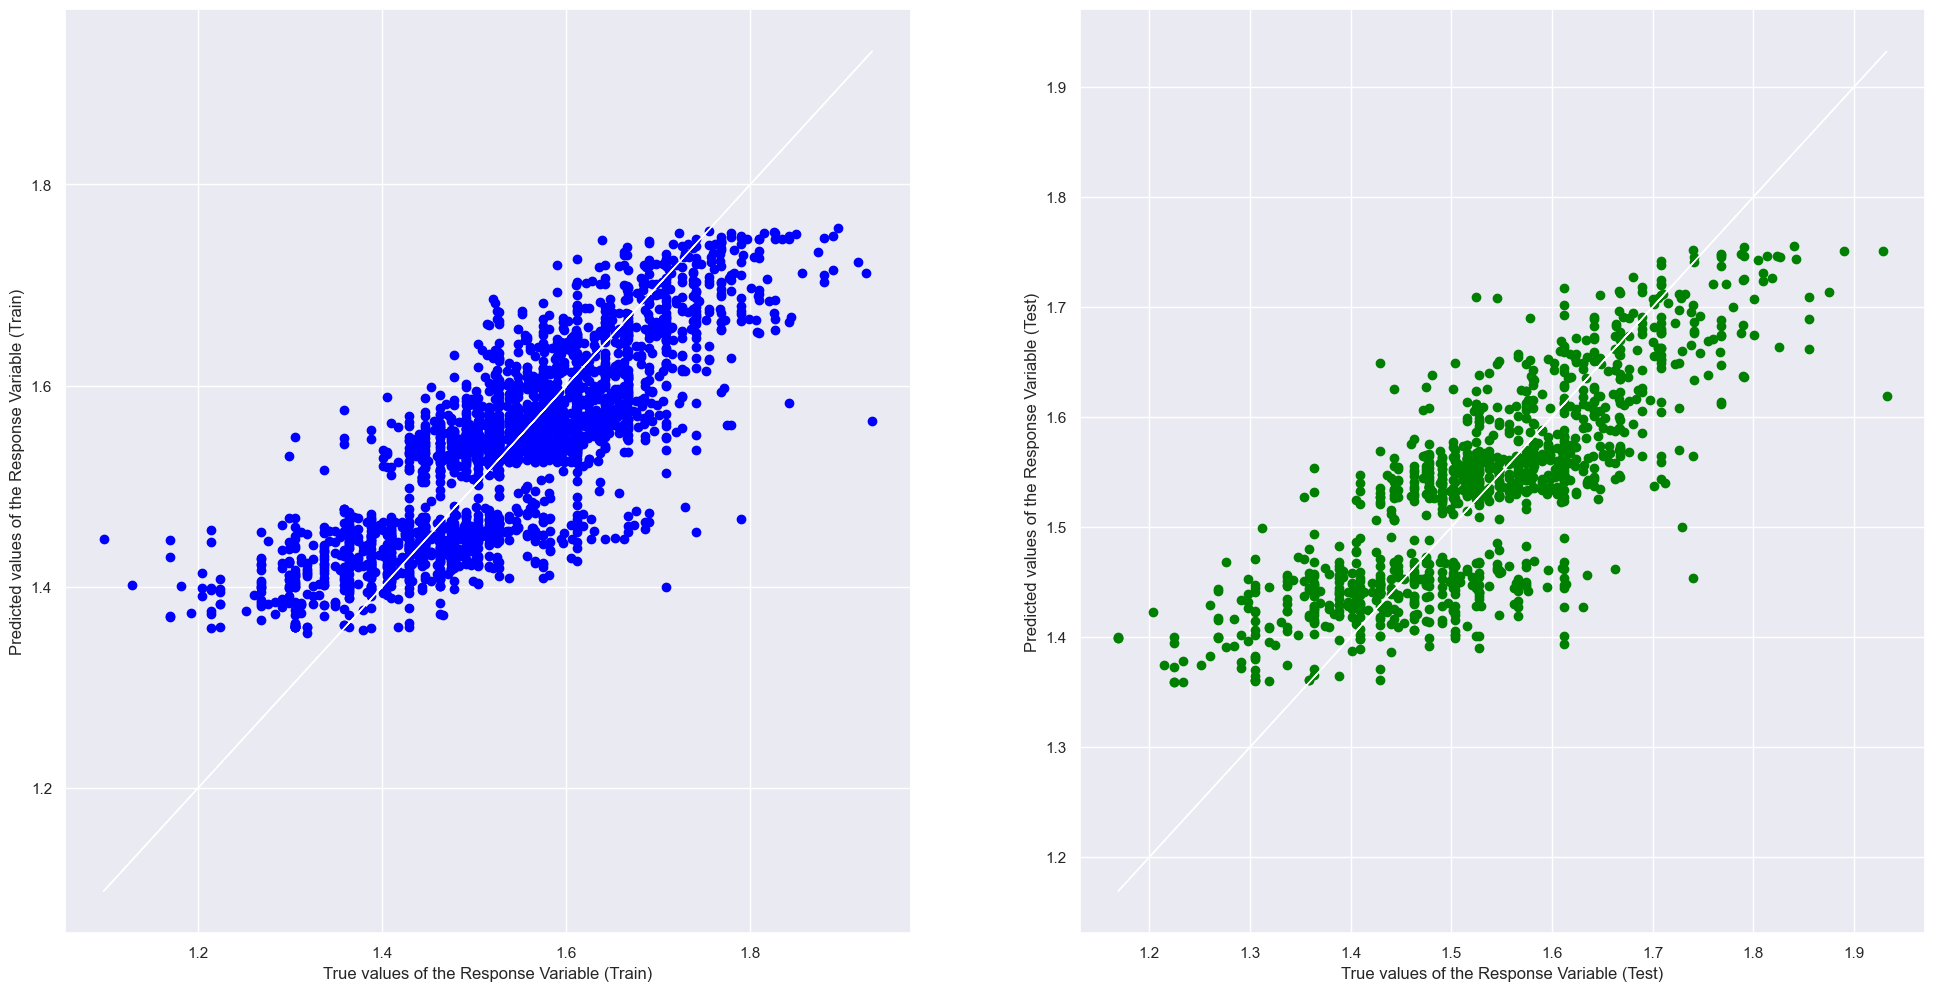

In [725]:
f, axes = plt.subplots(1, 2, figsize=(24, 12))
axes[0].scatter(y_train, y_train_pred, color = "blue")
axes[0].plot(y_train, y_train, 'w-', linewidth = 1)
axes[0].set_xlabel("True values of the Response Variable (Train)")
axes[0].set_ylabel("Predicted values of the Response Variable (Train)")
axes[1].scatter(y_test, y_test_pred, color = "green")
axes[1].plot(y_test, y_test, 'w-', linewidth = 1)
axes[1].set_xlabel("True values of the Response Variable (Test)")
axes[1].set_ylabel("Predicted values of the Response Variable (Test)")
plt.show()

Sample of predicted price vs actual price

In [727]:
results = pd.DataFrame({'Actual': y_test["price"]**10, 'Predicted': y_test_pred**10})
results.sample(n=20)

,Actual,Predicted
id,,
8759443,18.218436,36.973159
1537246,107.398547,78.539733
5319948,35.499626,47.362163
5365612,22.300657,37.530534
3294243,118.160441,141.407090
8474584,47.669744,87.689706
4360485,33.676277,38.669741
6837338,49.580188,39.974106
9474025,35.499626,23.539919


Hyperparamter tuning using GridSearchCV

In [342]:
import time
from sklearn.model_selection import GridSearchCV
param_grid = { 
    'n_estimators': [300,400,500,600],
    'max_features': ['sqrt', 'log2'],
    'max_depth' : [10,15,20,30],
    'criterion' :["squared_error", "absolute_error", "friedman_mse", "poisson"],
    'min_samples_leaf' :[5,10,20,30],
    'min_samples_split' :[5,10,15,20]
}
start_time = time.time()
CV_rf = GridSearchCV(estimator=RFreg, param_grid=param_grid, cv= 5,n_jobs=-1)
CV_rf.fit(X_train, y_train.values.ravel())
elapsed_time = time.time() - start_time
print(f"Elapsed time to compute: {elapsed_time:.3f} seconds")

Elapsed time to compute: 3269.330 seconds


In [343]:
CV_rf.best_params_

{'criterion': 'friedman_mse',
 'max_depth': 20,
 'max_features': 'sqrt',
 'min_samples_leaf': 5,
 'min_samples_split': 5,
 'n_estimators': 400}

#### Experimenting with different models 

In [764]:
def RegressorsModel(X_train_regr, X_test_regr, y_train_regr, y_test_regr):
    
    GradRegr = GradientBoostingRegressor(n_estimators=600,min_samples_leaf=50,min_samples_split=20,max_depth=2) 
    Model(GradRegr, "Gradient Boosting Regressor", X_train_regr, X_test_regr, y_train_regr, y_test_regr)
    
    AdaRegr = AdaBoostRegressor(n_estimators=600)
    Model(AdaRegr, "AdaBoost Regressor", X_train_regr, X_test_regr, y_train_regr, y_test_regr)

In [765]:
def Model(data, modeln, X_train_regr, X_test_regr, y_train_regr, y_test_regr):

    data.fit(X_train_regr, y_train_regr)
    y_train_pred = data.predict(X_train_regr)
    y_test_pred = data.predict(X_test_regr)
    
    # Check the Goodness of Fit (on Train Data)
    print(modeln)
    print()
    print("Goodness of Fit of Model \tTrain Dataset")
    print("Explained Variance (R^2) \t:", data.score(X_train_regr, y_train_regr))
    print("Mean Squared Error (MSE) \t:", mean_squared_error(y_train_regr, y_train_pred))
    print()
    
    # Check the Goodness of Fit (on Test Data)
    print("Goodness of Fit of Model \tTest Dataset")
    print("Explained Variance (R^2) \t:", data.score(X_test_regr, y_test_regr))
    print("Mean Squared Error (MSE) \t:", mean_squared_error(y_test_regr, y_test_pred))
    print()
    
    # Plot the Predictions vs the True values
    f, axes = plt.subplots(1, 2, figsize=(24, 12))
    axes[0].scatter(y_train_regr, y_train_pred, color = "red")
    axes[0].plot(y_train_regr, y_train_regr, 'w-', linewidth = 1)
    axes[0].set_xlabel("Train Data Response Variable True Values ")
    axes[0].set_ylabel("Train Data Response Variable Predicted Values")
    axes[1].scatter(y_test_regr, y_test_pred, color = "blue")
    axes[1].plot(y_test_regr, y_test_regr, 'w-', linewidth = 1)
    axes[1].set_xlabel("Test Data Response Variable True Values")
    axes[1].set_ylabel("Test Data Response Variable Predicted Values")
    plt.show()

Gradient Boosting Regressor

Goodness of Fit of Model 	Train Dataset
Explained Variance (R^2) 	: 0.6990571529486177
Mean Squared Error (MSE) 	: 0.004325786754333068

Goodness of Fit of Model 	Test Dataset
Explained Variance (R^2) 	: 0.6610052327565424
Mean Squared Error (MSE) 	: 0.0050239473395283125



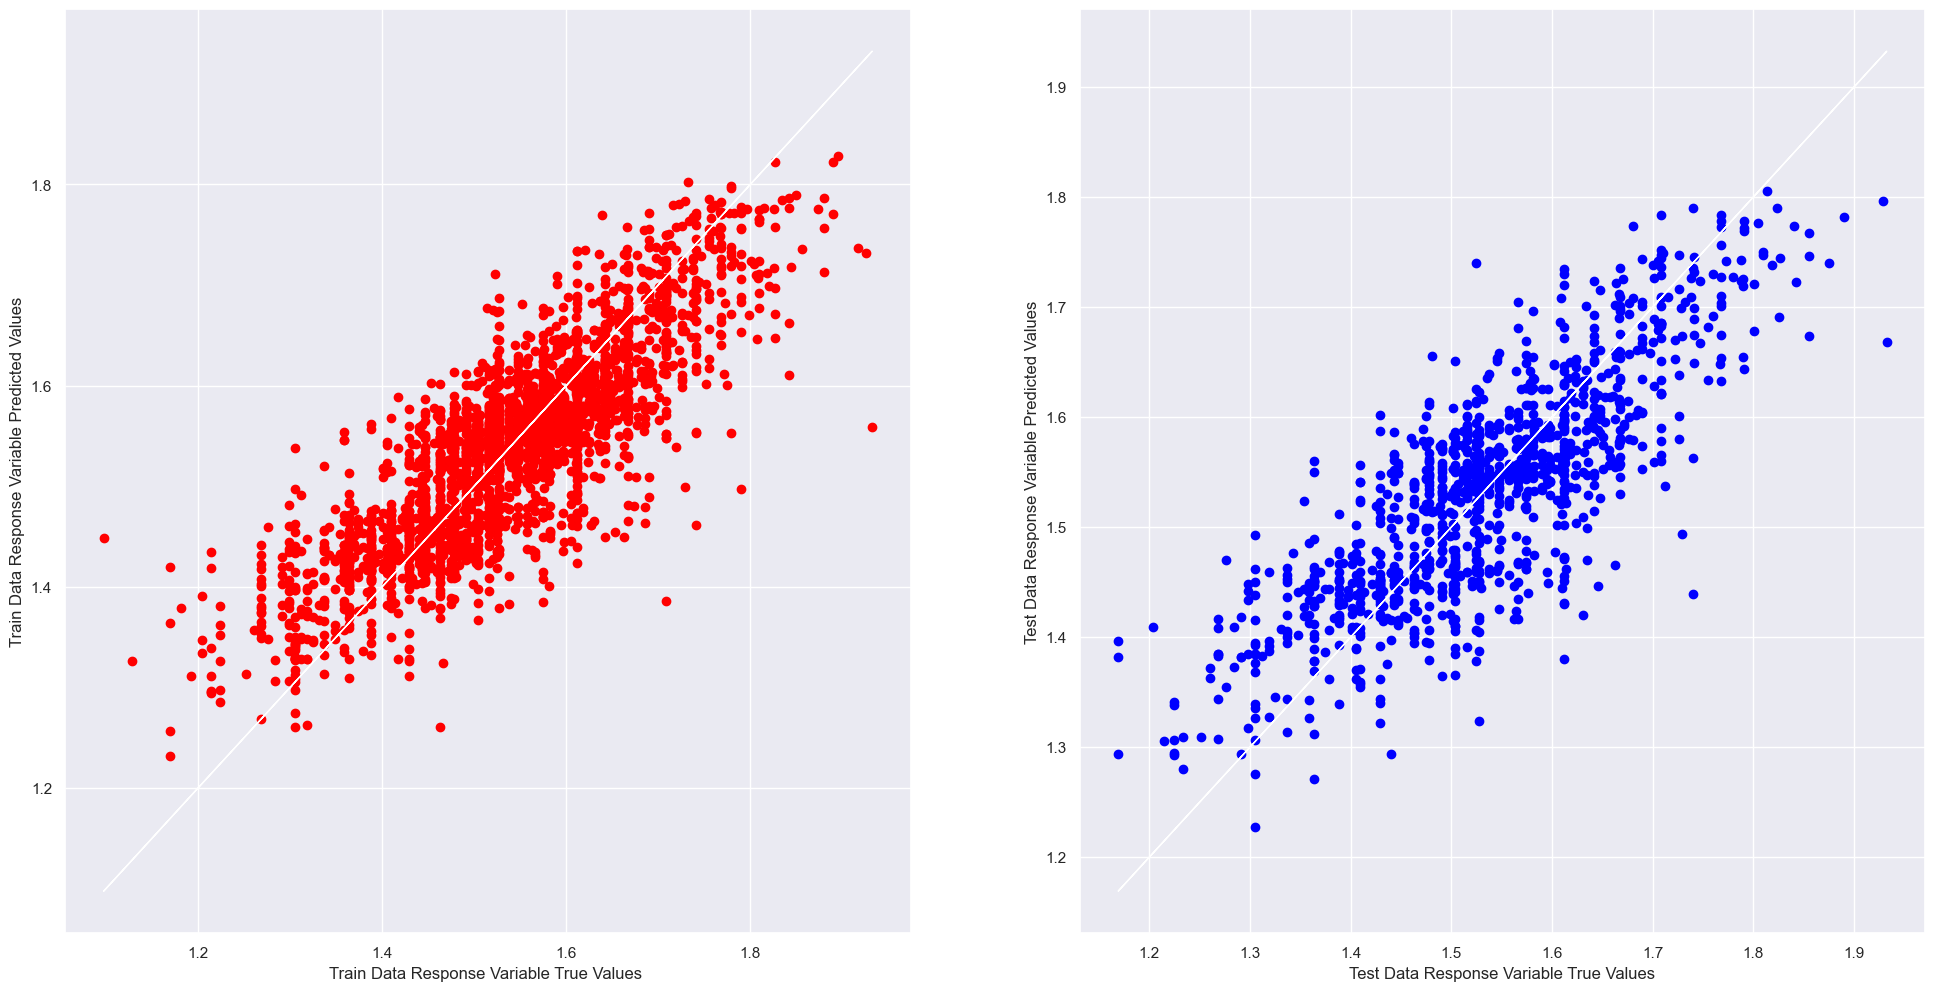

AdaBoost Regressor

Goodness of Fit of Model 	Train Dataset
Explained Variance (R^2) 	: 0.5848327116798753
Mean Squared Error (MSE) 	: 0.005967661880798719

Goodness of Fit of Model 	Test Dataset
Explained Variance (R^2) 	: 0.5883286008057834
Mean Squared Error (MSE) 	: 0.006101024648726633



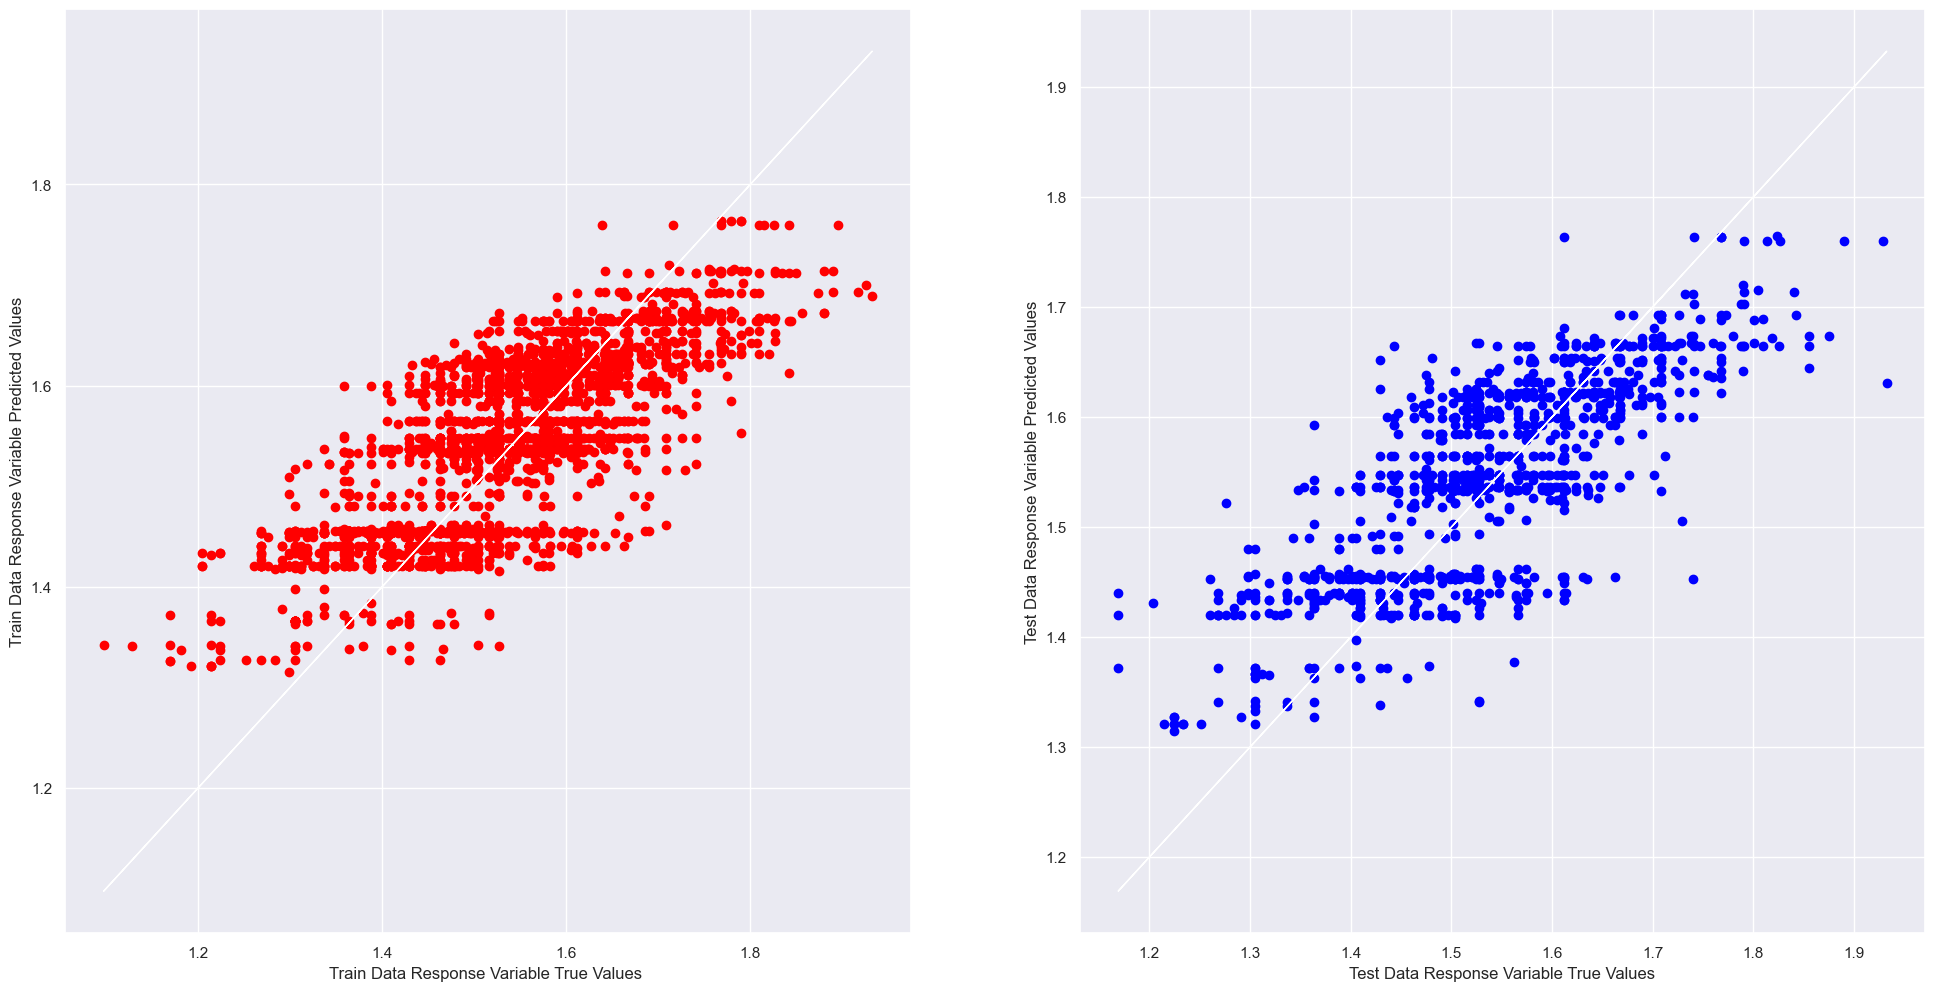

In [766]:
RegressorsModel(X_train, X_test, y_train.values.ravel(), y_test.values.ravel())